# Агентное управление S&OE-циклом импорта

Аналитический отчет по имитационной модели. Кейс «Мультиагентный S&OE-цикл импорта», Logus Nova 2026.
Расчет от 11.10.2026, 500 вариантов на каждый режим.

> **Все данные в отчете модельные.** Расположение 41 регионального РЦ взято из открытых данных, все остальное
> синтетическое: спрос, сроки, документы, экономика. Импорт приходит в федеральный транспортный центр (дальше —
> федеральный ТЦ) и оттуда расходится по РЦ. Результаты показаны только в относительных величинах: процентах,
> индексах, долях и кратностях.

> **Какую LLM используют агенты.** ИИ-агенты в проекте используют LLM (большую языковую модель) GigaChat от Сбера
> через GigaChat API. Она читает письма, PDF и документы и объясняет решения человеку, но чисел не считает: прогноз
> сроков и расчет рычагов делают ML-модели и оркестратор. В варианте «Агенты без LLM» агенты работают без нее. Дальше
> в отчете — просто LLM.

## Главное

Мы сравнили два способа вести один и тот же поток импорта. В обоих работает S&OE: контейнер не закреплен за
регионом, товар лежит общим запасом в федеральном ТЦ и уходит регионам по их заявкам, отклонения разбирают на
еженедельной встрече. Разница в том, кто собирает данные, составляет заявки и готовит решения: планировщики вручную
или агенты. Штат людей одинаковый, стоимость работы агентов вычтена.

- С агентами прибыль потока импорта выше на **2,8 %** в обычном режиме, на **4,7 %**, когда
  терминалы загружены, как в 2026 году, и на **2,9 %** при сбое.
- С агентами теряется на 35 % меньше продаж. Эффект в 27 раз больше того, во что обходится работа агентов.
  В обычном режиме агенты выигрывают в 98 % вариантов.
- Основной выигрыш дает скорость. Агенты узнают о задержке и считают решение в тот же день, а у планировщиков события
  ждут в очереди. Но дело не только в нехватке людей: даже если планировщиков сколько угодно, агенты дают еще
  +1,1 % прибыли.
- Оркестратор оценивает рычаг по 16 сценариям прихода грузов, а не по одному сроку. Только это дает +0,6 % прибыли
  (раздел 8).
- LLM нужна для того, чего не умеют правила: читать письма экспедиторов и брокеров, поток статусов и документы
  свободной формы. Чем напряженнее поставки, тем больше ее вклад: 3 % эффекта агентов в обычном режиме,
  6 % при загрузке 2026 года и 38 %, когда товар приходит впритык к продажам
  (там LLM дает плюс в 99 % вариантов). Подробнее в разделе 9.
- Больше всего дает приоритетный вывоз с СВХ: 65 % эффекта. Его цена — наше допущение: в публичных
  тарифах такой услуги нет. Без этого рычага агенты дают около +0,9 % прибыли.
- Чем меньше запаса в пути, тем нужнее агенты. При запасе вдвое меньше базового эффект +3,4 %, при запасе в 2,3 раза
  больше — +0,4 %.

**Прибыль потока импорта** здесь — маржа проданного товара за вычетом перевозок, хранения, цены рычагов, денег,
замороженных в запасе, и уценки.

## Содержание

1. [Задача и как мы проверяем эффект](#1)
2. [Модельная сеть: РЦ и точки входа](#2)
3. [Допущения и источники](#3)
4. [Как идет контейнер: сроки по этапам](#4)
5. [ML-агенты сроков: точность и калибровка](#5)
6. [Как это работает на одном варианте](#6)
7. [Монте-Карло: результат и его надежность](#7)
8. [Как оркестратор решает, включать ли рычаг](#8)
9. [Где нужна LLM](#9)
10. [Когда агенты нужнее всего](#10)
11. [Проверки модели](#11)
12. [Пример: разбор одного контейнера агентами](#12)
13. [Приложение: сезонный товар](#13)
14. [Ограничения и что нужно для пилота](#14)

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from analysis import style as S, lib, charts
from analysis.style import ACCENT, ACCENT_L, INK, G1, G2, G3, G4, RULE_COLOR, RULE_NAME, SCEN_NAME, num, pct, spct, pp

S.setup()
RES = json.loads((ROOT / "outputs/model_v5/results.json").read_text(encoding="utf-8"))
RUNS = pd.read_csv(ROOT / "outputs/model_v5/runs.csv")
STAFF_RUNS = pd.read_csv(ROOT / "outputs/model_v5/runs_staff.csv")
P, NET, ETA, SCEN, STAFF = lib.world()
MAIN = ["general", "general_2026", "general_shock"]
RULES3 = ["P1", "P2a", "P2"]
U, PRICE, MARGIN = P["product"]["units_per_container"], P["product"]["price_rub"], P["product"]["margin"]
CM = U * PRICE * MARGIN            # маржа одного контейнера: база для относительных цен рычагов
N0 = int(P["v4"]["volume"]["containers_base"])
print(f"Модельные данные: {RES['runs']} вариантов на режим, {RES['rcs']} региональный РЦ, штат одинаковый во всех вариантах управления.")

Модельные данные: 500 вариантов на режим, 41 региональный РЦ, штат одинаковый во всех вариантах управления.


<a id="1"></a>
## 1. Задача и как мы проверяем эффект

Сроки импорта плохо предсказуемы. Контейнер задерживается на границе, таможня запрашивает дополнительные документы,
терминал неделями не может вывезти груз на ж/д. О задержке обычно узнают из статусов экспедитора и писем, и часто уже
тогда, когда в регионе кончился товар.

Мы проверяем, приносят ли агенты дополнительную прибыль компании, которая уже работает по S&OE, при том же штате
людей.

**Три варианта управления**

| Вариант | Как устроен |
|---|---|
| S&OE без агентов | контейнер не закреплен за регионом; товар лежит общим запасом в федеральном ТЦ и уходит регионам по их заявкам; отклонения разбирают на еженедельной встрече. Заявки составляют региональные планировщики, и каждый регион завышает свою по-своему. Данные о грузах собирают и решения готовят планировщики вручную, по статусам и письмам |
| Агенты без LLM | тот же S&OE, но заявку региона составляет агент региона по прогнозу спроса с учетом потерянных продаж, сроки прогнозирует ML, рычаги считает оркестратор, решения готовятся в тот же день. Агенты читают только структурированные данные (трекинг, EDI, статусы терминалов) и документы стандартной формы |
| Агенты с LLM | то же, плюс LLM читает письма, PDF и сообщения экспедиторов и брокеров и сверяет документы любой формы; ее ошибки учтены |

Эффект агентов — на сколько процентов прибыль в варианте «Агенты с LLM» выше, чем в S&OE без агентов, после стоимости
работы агентов (сервер, поддержка, токены LLM). Дальше «с агентами» означает этот вариант.

**Как устроен эксперимент.** Модель проживает 120 дней день за днем. Мы прогнали 500 случайных вариантов спроса,
задержек, проверок и очередей. В каждом варианте все три способа управления видят одни и те же события, поэтому
разница между ними объясняется управлением, а не везением.

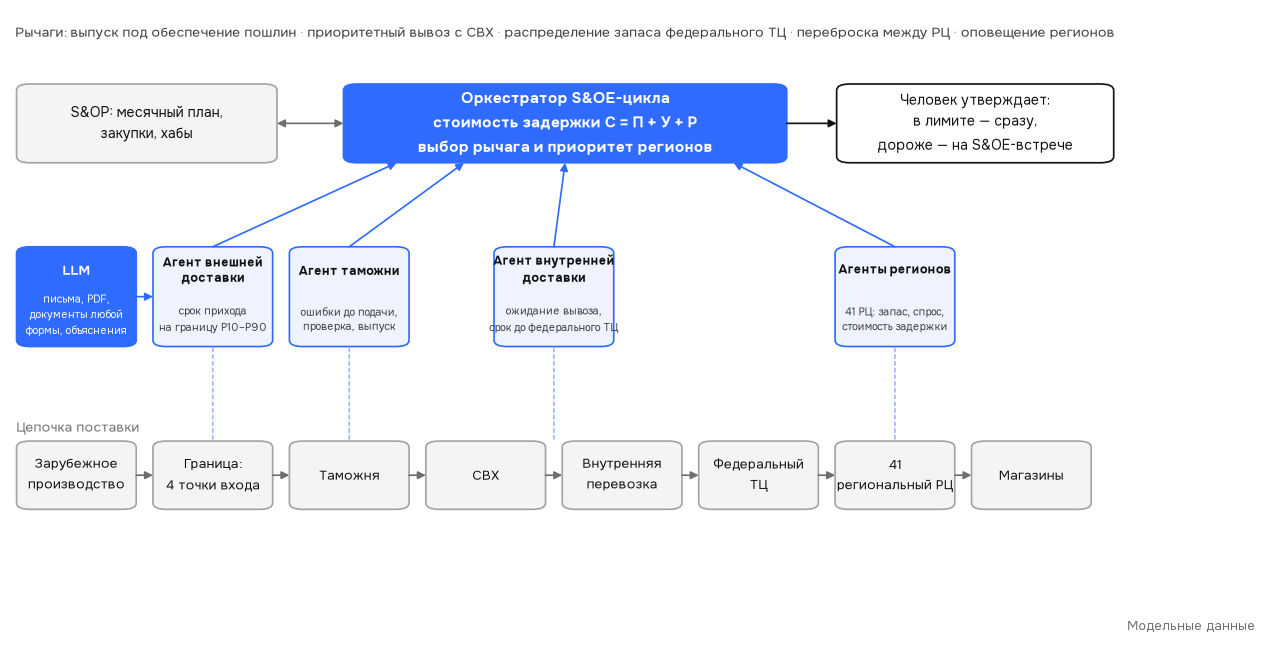

In [2]:
fig = charts.scheme()
S.show(fig)

<a id="2"></a>
## 2. Модельная сеть: РЦ и точки входа

В сети 41 региональный РЦ. Доля РЦ в спросе равна доле магазинов, для которых он ближайший. Импорт приходит в
федеральный ТЦ; в ближние РЦ товар везут автомобилем, в дальние (дальше 1 500 км, это допущение) — по ж/д.

In [3]:
rc = pd.DataFrame(NET.raw["rcs"])
rc["short"] = rc["name"].str.extract(r"«([^»]+)»")[0].fillna(rc["name"])
rc.loc[rc.is_federal, "short"] = "федеральный ТЦ"
rc["days"] = NET.from_fed_days
fd = (rc.groupby("fd").agg(share=("share", "sum"), rail=("mode", lambda m: (m != "авто").mean()), days=("days", "mean"))
        .sort_values("share", ascending=False))
t = pd.DataFrame({"Доля спроса": fd.share.map(lambda x: pct(x, 1)), "Доля РЦ, куда везут по ж/д": fd.rail.map(pct),
                  "Доставка из федерального ТЦ, сут (в среднем)": fd.days.map(lambda x: num(x, 1))})
t.index.name = "Федеральный округ"
S.table(t)

,Доля спроса,"Доля РЦ, куда везут по ж/д","Доставка из федерального ТЦ, сут (в среднем)"
Федеральный округ,,,
Центральный,"31,0 %",0 %,"1,3"
Приволжский,"24,9 %",0 %,"2,7"
Южный,"15,2 %",0 %,"3,1"
Уральский,"10,4 %",100 %,"5,5"
Северо-Западный,"9,6 %",25 %,"2,9"
Сибирский,"5,4 %",100 %,"8,1"
Северо-Кавказский,"2,3 %",100 %,"4,8"
Дальневосточный,"1,3 %",100 %,"14,8"


<sub><i>Модельные данные.</i></sub>

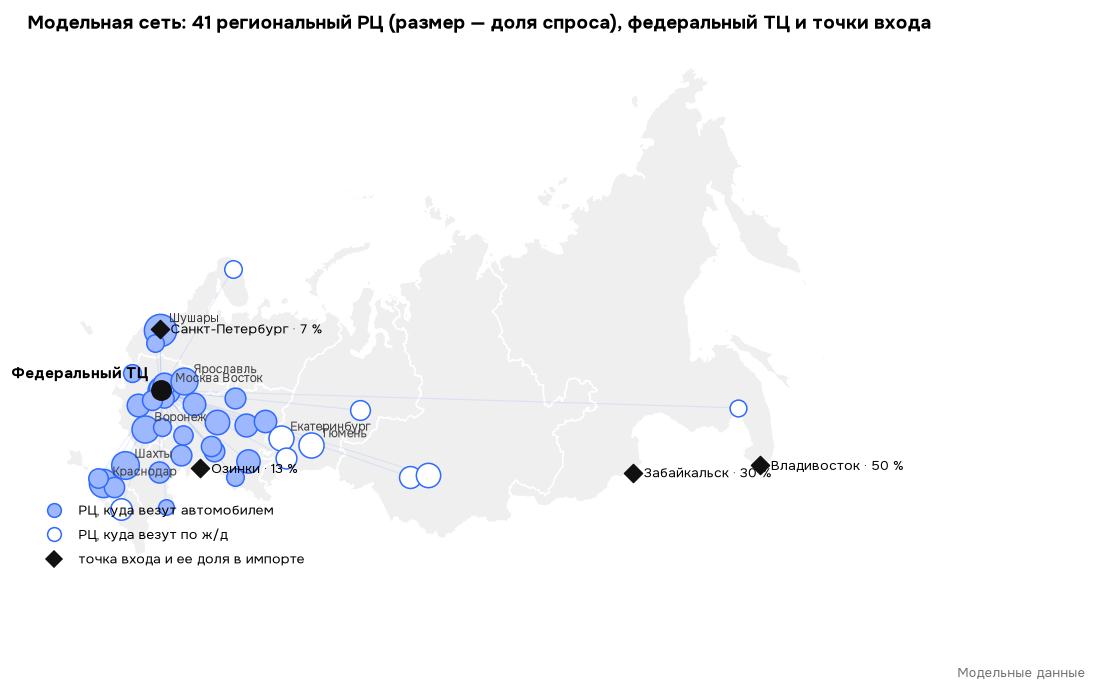

In [4]:
fig, ax = charts.network_map(rc.to_dict("records"), NET.raw["gateways"])
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc=ACCENT_L, mec=ACCENT, ms=9, label="РЦ, куда везут автомобилем"),
                   Line2D([], [], marker="o", ls="", mfc="white", mec=ACCENT, ms=9, label="РЦ, куда везут по ж/д"),
                   Line2D([], [], marker="D", ls="", color=INK, ms=7, label="точка входа и ее доля в импорте")],
          loc="lower left", fontsize=9)
ax.set_title("Модельная сеть: 41 региональный РЦ (размер — доля спроса), федеральный ТЦ и точки входа")
S.show(fig)

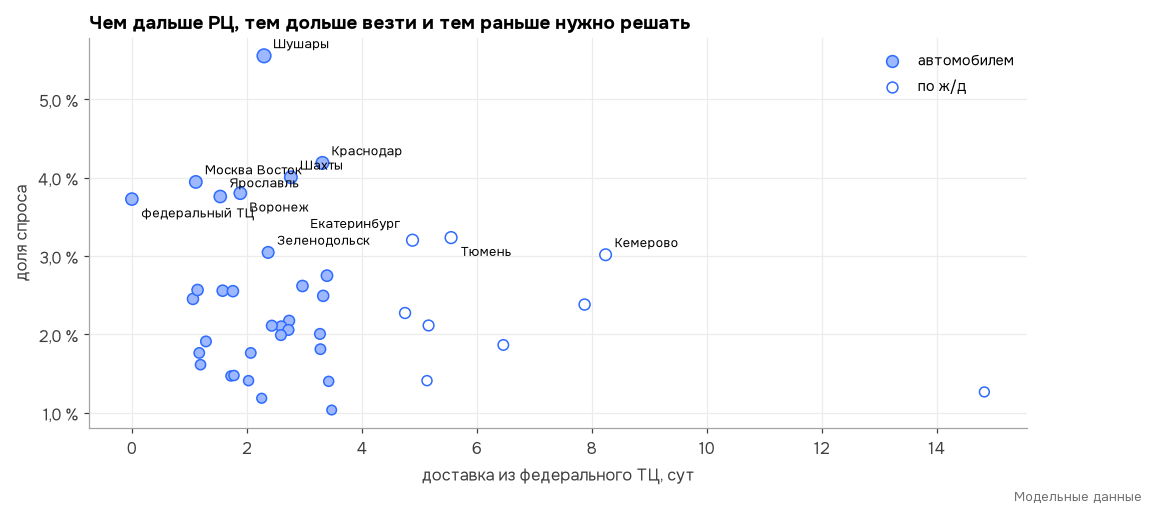

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.6))
auto = rc["mode"] == "авто"
ax.scatter(rc.days[auto], rc.share[auto], s=30 + 900 * rc.share[auto], color=ACCENT_L, ec=ACCENT, label="автомобилем")
ax.scatter(rc.days[~auto], rc.share[~auto], s=30 + 900 * rc.share[~auto], color="white", ec=ACCENT, label="по ж/д")
OFF = {"федеральный ТЦ": (6, -12), "Ярославль": (6, 6), "Воронеж": (6, -12), "Екатеринбург": (-8, 8), "Тюмень": (6, -12)}
for _, r in rc.sort_values("share", ascending=False).head(11).iterrows():
    dx, dy = OFF.get(r.short, (6, 5))
    ax.annotate(r.short, (r.days, r.share), xytext=(dx, dy), textcoords="offset points", fontsize=8.5, ha="right" if dx < 0 else "left")
ax.set_xlabel("доставка из федерального ТЦ, сут")
ax.set_ylabel("доля спроса")
ax.yaxis.set_major_formatter(S.fmt_pct(1))
ax.set_title("Чем дальше РЦ, тем дольше везти и тем раньше нужно решать")
ax.legend(loc="upper right")
S.show(fig)

In [6]:
svh_base = P["v5"]["eta"]["svh"]["base"]
gw = pd.DataFrame([{"Точка входа": g.name, "Доля импорта": pct(g.share), "Обычное ожидание вывоза с СВХ, сут": num(svh_base[k]),
                    "Внутренняя перевозка до федерального ТЦ, сут": num(NET.gw_km[k] / NET.speed, 1)}
                   for k, g in enumerate(NET.gateways) if g.share > 0]).set_index("Точка входа")
S.table(gw)

,Доля импорта,"Обычное ожидание вывоза с СВХ, сут","Внутренняя перевозка до федерального ТЦ, сут"
Точка входа,,,
Владивосток,50 %,8,"13,4"
Забайкальск,30 %,10,"10,7"
Озинки,13 %,8,"1,9"
Санкт-Петербург,7 %,3,"1,4"


<sub><i>Модельные данные.</i></sub>

<a id="3"></a>
## 3. Допущения и источники

Все параметры лежат в `config/params.yaml`. У фактов указан источник, у допущений — пометка и диапазон. Денежные
параметры показаны в долях маржи одного контейнера. Ключевые допущения проверены на чувствительность (раздел 10).
Источники по таможне и складам временного хранения (СВХ) — в `docs/sources.md`.

In [7]:
cu, sv, hb, ch = P["v5"]["customs"], P["v5"]["svh"], P["v5"]["hub"], P["v5"]["channels"]
guar = U * cu["customs_value_rub"] * (cu["duty_rate"] + cu["vat"] * (1 + cu["duty_rate"])) * cu["guarantee_rate_year"] * cu["guarantee_min_days"] / 365
C0, L0, F0, DM0, COST0 = lib.rel_runs(RUNS, "general", P, RES)
ac = P["v4"]["agents_cost"]
fixed = 120 / (365 / 12) * (ac["server_rub_month"] + ac["support_fte"] * ac["developer_rub_month"])
tok_share = (COST0 - fixed).mean() / COST0.mean()
I, D, E = "источник", "допущение", "оценка по источнику"
rows = [
    ("Маржа", pct(MARGIN), D, "доля цены"),
    ("Стоимость денег в запасе", pct(P["economics"]["money_rate"]) + " годовых", I, "ключевая ставка, нижняя граница"),
    ("Запас в пути и на складе", "около 10 дней продаж", D, "контейнеры приходят равномерно, закупка равна прогнозу"),
    ("Разброс спроса РЦ относительно плана", pct(P["v5"]["demand"]["level_sigma"]), D, "логнормальный"),
    ("Завышение заявок региональными планировщиками", f"{pct(P['sim']['p0_overorder_range'][0])}–{pct(P['sim']['p0_overorder_range'][1])}", D,
     "у каждого региона свое; агенты регионов составляют заявку по прогнозу без завышения"),
    ("Ожидание вывоза с СВХ", " / ".join(num(x) for x in svh_base[:4]) + " сут", E, "Владивосток, Забайкальск, Озинки — STALOGISTIC 07.10.2026, «Интер-Фрейт»; Санкт-Петербург — допущение"),
    ("Доля деклараций с дополнительной проверкой", pct(cu["check_share"]), E, "доклад ФТС за 2025 год"),
    ("Длительность проверки", f"{num(cu['check_days'][0])}–{num(cu['check_days'][1])} сут", E, "ТК ЕАЭС, ст. 119"),
    ("Доля поставок с ошибкой в документах", pct(cu["doc_error_share"]), E, "ФТС: возвраты деклараций около 1,5 % в день"),
    ("Сколько ошибок находит сверка", pct(cu["ocr_catch"]), D, ""),
    ("Новости о задержках в структурированном виде", pct(ch["structured_share"]), D, "трекинг, EDI, статусы терминалов и РЖД; остальное — письма, PDF, мессенджеры (диапазон 20–70 %)"),
    ("Документы стандартной формы", pct(ch["doc_template_share"]), D, "их сверяют правила; свободные формы и сканы — только LLM (30–80 %)"),
    ("Ошибки LLM", pct(P["v4"]["llm"]["error_rate"]), D, "четверть из них — пропущенная новость (5–20 %)"),
    ("Пошлина", pct(cu["duty_rate"]), D, "для условной товарной категории"),
    ("НДС на ввоз", pct(cu["vat"]), I, "425-ФЗ"),
    ("Цена выпуска под обеспечение", pct(guar / CM, 2) + " маржи контейнера", E, "банковская гарантия 2 % годовых на 90 дней (ВТБ — от 0,9 %)"),
    ("Бесплатное хранение на СВХ", f"{num(sv['free_days'])} сут", I, "тариф ВМТП"),
    ("Хранение сверх бесплатного", pct(sv["storage_rub_day"] / CM, 2) + " маржи контейнера в сутки", I, "тариф ВМТП"),
    ("Цена приоритетного вывоза", pct(sv["priority_fee_rub"] / CM, 1) + " маржи контейнера", D, "в тарифах такой услуги нет; диапазон ×0,4 … ×3"),
    ("Ожидание при приоритетном вывозе", f"{num(sv['priority_wait_days'])} сут", E, "STALOGISTIC: отправка «от 2 суток»"),
    ("Пересмотр отгрузок / страховой запас РЦ", f"каждые {num(hb['review_days'])} дня / {num(hb['safety_days'])} дней продаж", D, ""),
    ("Лимит решения без встречи", pct(P["v4"]["corridor"]["limit_rub"] / CM) + " маржи контейнера", D, ""),
    ("Стоимость работы агентов", pct(COST0.mean() / (DM0 - C0["P1"]).mean(), 2) + " прибыли потока", D, f"сервер и поддержка; токены LLM — {pct(tok_share)} стоимости"),
]
S.table(pd.DataFrame(rows, columns=["Параметр", "Значение", "Тип", "Комментарий и источник"]).set_index("Параметр"))

,Значение,Тип,Комментарий и источник
Параметр,,,
Маржа,35 %,допущение,доля цены
Стоимость денег в запасе,14 % годовых,источник,"ключевая ставка, нижняя граница"
Запас в пути и на складе,около 10 дней продаж,допущение,"контейнеры приходят равномерно, закупка равна ..."
Разброс спроса РЦ относительно плана,20 %,допущение,логнормальный
Завышение заявок региональными планировщиками,10 %–20 %,допущение,у каждого региона свое; агенты регионов состав...
Ожидание вывоза с СВХ,8 / 10 / 8 / 3 сут,оценка по источнику,"Владивосток, Забайкальск, Озинки — STALOGISTIC..."
Доля деклараций с дополнительной проверкой,7 %,оценка по источнику,доклад ФТС за 2025 год
Длительность проверки,5–14 сут,оценка по источнику,"ТК ЕАЭС, ст. 119"
Доля поставок с ошибкой в документах,3 %,оценка по источнику,"ФТС: возвраты деклараций около 1,5 % в день"


<sub><i>Модельные данные.</i></sub>

<a id="4"></a>
## 4. Как идет контейнер: сроки по этапам

Ниже один вариант режима «загрузка 2026 года». Задержка до границы и ожидание вывоза с СВХ зависят от загрузки
точки входа. Загрузка меняется волнами и держится неделями, поэтому опаздывает не один контейнер, а все, кто приходит
в эти дни. Именно это и позволяет прогнозировать сроки.

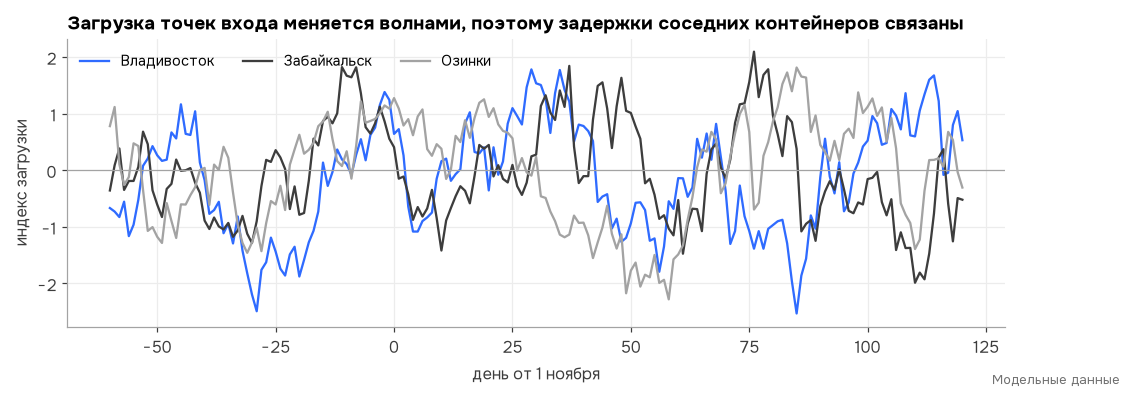

In [8]:
s4 = lib.season_for("general_2026", 101, "P2")
names = [g.name for g in NET.gateways]
fig, ax = plt.subplots(figsize=(11, 3.4))
days = np.arange(-60, 121)
for k, c in zip([0, 1, 2], [ACCENT, G1, G3]):
    ax.plot(days, s4.d.cong[k, days + 200], color=c, lw=1.5, label=names[k])
ax.axhline(0, color=G3, lw=0.8)
ax.set_xlabel("день от 1 ноября")
ax.set_ylabel("индекс загрузки")
ax.set_title("Загрузка точек входа меняется волнами, поэтому задержки соседних контейнеров связаны")
ax.legend(ncol=3, loc="upper left")
S.show(fig)

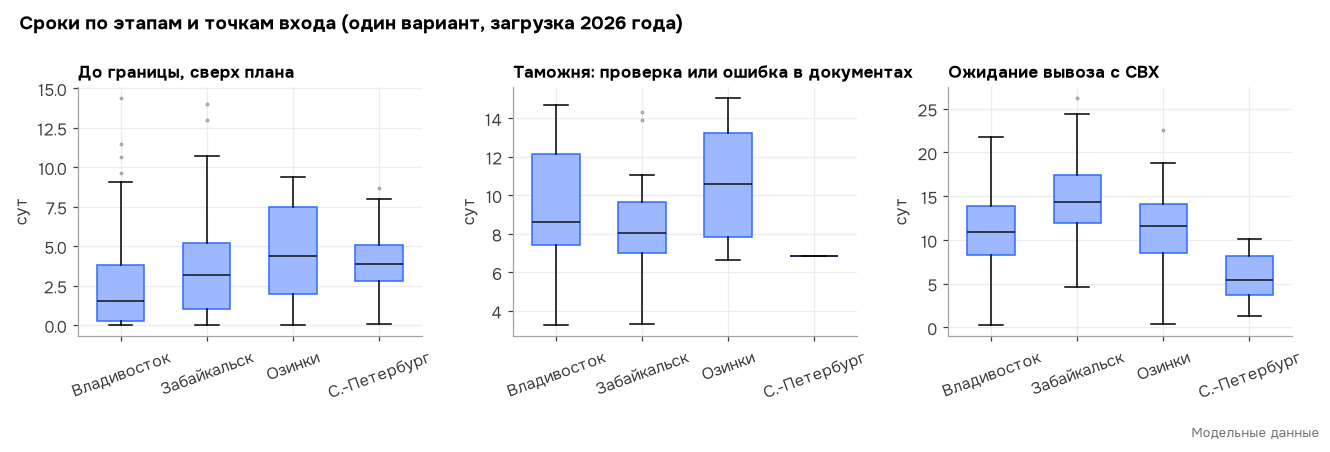

Дополнительную проверку таможня назначила 7 % контейнеров, ошибка в документах — у 3,4 %. Обычный выпуск занимает сутки, поэтому на среднем графике только эти контейнеры.

In [9]:
comp = pd.DataFrame({"Точка входа": [names[g] for g in s4.gw], "До границы, сверх плана": s4.ext,
                     "Таможня": s4.custom_days, "Ожидание вывоза с СВХ": s4.wait})
extra_c = s4.custom_days > s4.cu["release_days"] + 1e-9
order = [n for n in names if (comp["Точка входа"] == n).any()]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, col in zip(axes, ["До границы, сверх плана", "Таможня", "Ожидание вывоза с СВХ"]):
    sel = extra_c if col == "Таможня" else np.ones(len(comp), bool)
    data = [comp.loc[(comp["Точка входа"] == n) & sel, col] for n in order]
    b = ax.boxplot(data, orientation="vertical", patch_artist=True, widths=0.55, showfliers=True,
                   medianprops=dict(color=INK), flierprops=dict(marker=".", ms=3, mec=G3))
    for patch in b["boxes"]:
        patch.set(facecolor=ACCENT_L, edgecolor=ACCENT)
    ax.set_xticks(range(1, len(order) + 1), [n.replace("Санкт-Петербург", "С.-Петербург") for n in order], rotation=20)
    ax.set_title(col if col != "Таможня" else "Таможня: проверка или ошибка в документах", fontsize=11)
    ax.set_ylabel("сут")
fig.suptitle("Сроки по этапам и точкам входа (один вариант, загрузка 2026 года)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
S.show(fig)
display(Markdown(f"Дополнительную проверку таможня назначила {pct(s4.chk.mean())} контейнеров, ошибка в документах — у "
                 f"{pct(s4.doc.mean(), 1)}. Обычный выпуск занимает сутки, поэтому на среднем графике только эти контейнеры."))

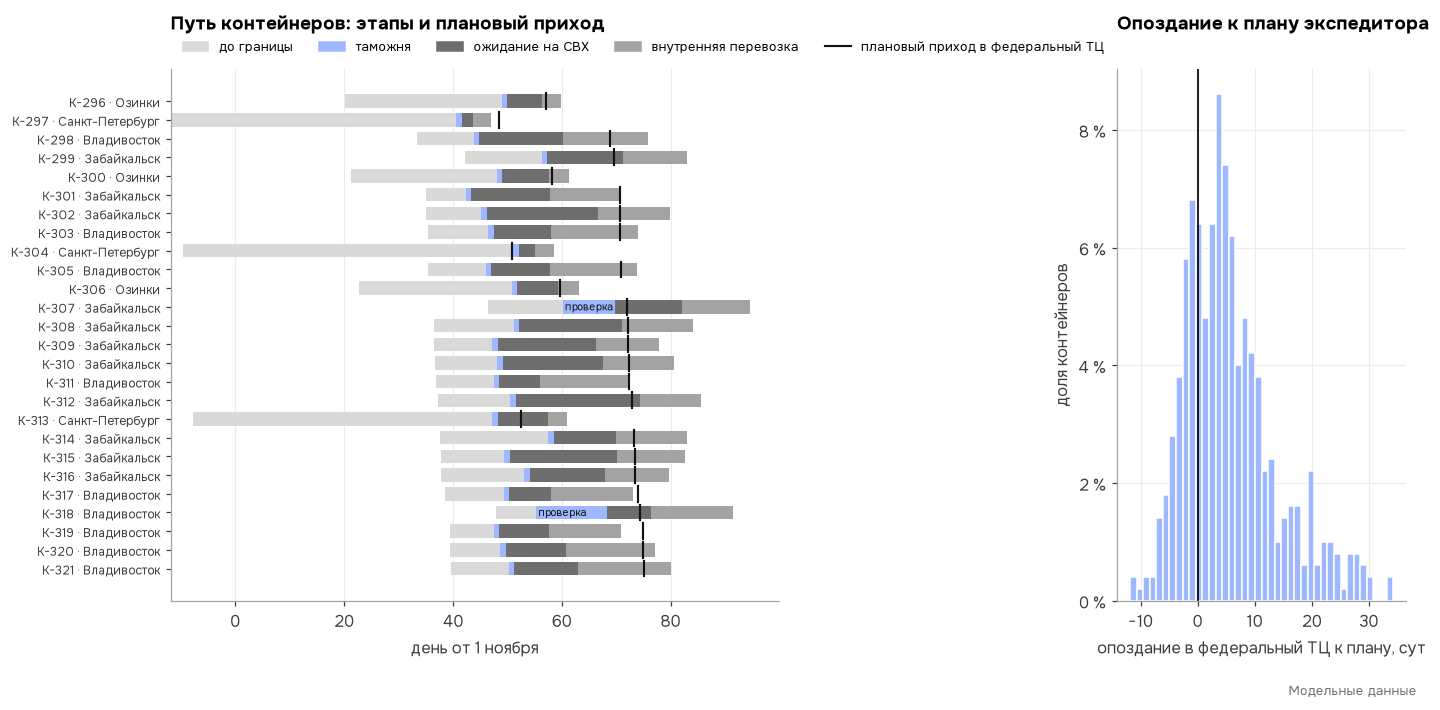

На 3 суток и больше опаздывают 60 % контейнеров, на 10 суток и больше — 23 %.

In [10]:
plan_fed = s4.plan + s4.cu["release_days"] + s4.plan_wait + NET.gw_km[s4.gw] / NET.speed + s4.hub_hand
late = s4.t_fed - plan_fed
idx = [i for i in np.argsort(s4.plan) if 40 <= s4.plan[i] <= 60][:26]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6.2), gridspec_kw={"width_ratios": [2.1, 1]})
charts.gantt(s4, idx, 0, ax1)
ax1.set_xlabel("день от 1 ноября")
ax1.set_title("Путь контейнеров: этапы и плановый приход", pad=26)
ax2.hist(late, bins=40, color=ACCENT_L, ec="white", weights=np.ones(len(late)) / len(late))
ax2.yaxis.set_major_formatter(S.fmt_pct())
ax2.axvline(0, color=INK, lw=1.2)
ax2.set_xlabel("опоздание в федеральный ТЦ к плану, сут")
ax2.set_ylabel("доля контейнеров")
ax2.set_title("Опоздание к плану экспедитора", pad=26)
fig.tight_layout()
S.show(fig)
display(Markdown(f"На 3 суток и больше опаздывают {pct((late > 3).mean())} контейнеров, на 10 суток и больше — {pct((late > 10).mean())}."))

<a id="5"></a>
## 5. ML-агенты сроков: точность и калибровка

Агенты сроков — это квантильная регрессия на градиентном бустинге (scikit-learn). Для каждого контейнера она дает три
оценки: оптимистичную (P10), вероятную (P50) и срок «не позже» (P90). Признаки — точка входа, индекс ее загрузки (в
жизни это данные портов, РЖД и экспедиторов), неделя и задержки оплаты. Модель обучена на синтетической истории трех
прошлых периодов и проверена на новых вариантах, которых не видела.

Если интервал P10–P90 честный, в него попадает около 80 % фактов, а ниже P50 — около половины. Ошибку сравниваем с
тем, чем пользуются планировщики: с планом экспедитора (его ошибка принята за 100 %) и со средним по прошлым периодам.

In [11]:
def eval_eta(scenario, seeds):
    out = []
    for sd in seeds:
        s = lib.season_for(scenario, sd, "P2")
        out.append(pd.DataFrame({"gw": [names[g] for g in s.gw], "ext": s.ext, "e10": s.q_ext[:, 0], "e50": s.q_ext[:, 1],
                                 "e90": s.q_ext[:, 2], "svh": s.wait, "w10": s.q_svh[:, 0], "w50": s.q_svh[:, 1],
                                 "w90": s.q_svh[:, 2], "plan_wait": s.plan_wait}))
    return pd.concat(out, ignore_index=True)

hist = eval_eta("general", range(3001, 3004))            # «прошлые периоды» для прогноза по среднему
mean_ext, mean_svh = hist.groupby("gw").ext.mean(), hist.groupby("gw").svh.mean()
ev = {sc: eval_eta(sc, range(2001, 2005)) for sc in ("general", "general_2026")}

def calib(e):
    return pd.Series({
        "до границы: в P10–P90": ((e.ext >= e.e10) & (e.ext <= e.e90)).mean(), "до границы: ниже P50": (e.ext < e.e50).mean(),
        "СВХ: в P10–P90": ((e.svh >= e.w10) & (e.svh <= e.w90)).mean(), "СВХ: ниже P50": (e.svh < e.w50).mean()})

def rel_err(e):
    pe, ps = e.ext.abs().mean(), (e.svh - e.plan_wait).abs().mean()
    return pd.DataFrame({
        "до границы": {"план экспедитора": 1.0, "среднее прошлых периодов": (e.ext - e.gw.map(mean_ext)).abs().mean() / pe,
                       "ML-агент (P50)": (e.ext - e.e50).abs().mean() / pe},
        "ожидание на СВХ": {"план экспедитора": 1.0, "среднее прошлых периодов": (e.svh - e.gw.map(mean_svh)).abs().mean() / ps,
                            "ML-агент (P50)": (e.svh - e.w50).abs().mean() / ps}})

cal = pd.DataFrame({SCEN_NAME[k]: calib(v) for k, v in ev.items()})
S.table(cal.map(pct).rename_axis("Калибровка (цель: 80 % и 50 %)"))
err = pd.concat({SCEN_NAME[k]: rel_err(v) for k, v in ev.items()}, axis=1)
S.table(err.map(pct).rename_axis("Средняя ошибка, % от ошибки плана"))

,Обычный режим,Загрузка 2026 года
Калибровка (цель: 80 % и 50 %),,
до границы: в P10–P90,78 %,78 %
до границы: ниже P50,49 %,49 %
СВХ: в P10–P90,77 %,33 %
СВХ: ниже P50,47 %,7 %


<sub><i>Модельные данные.</i></sub>

Обычный режим                  \
                                     до границы ожидание на СВХ   
Средняя ошибка, % от ошибки плана                                 
план экспедитора                          100 %           100 %   
среднее прошлых периодов                   70 %           102 %   
ML-агент (P50)                             52 %            59 %   

                                  Загрузка 2026 года                  
                                          до границы ожидание на СВХ  
Средняя ошибка, % от ошибки плана                                     
план экспедитора                               100 %           100 %  
среднее прошлых периодов                        70 %           155 %  
ML-агент (P50)                                  52 %           125 %

<sub><i>Модельные данные.</i></sub>

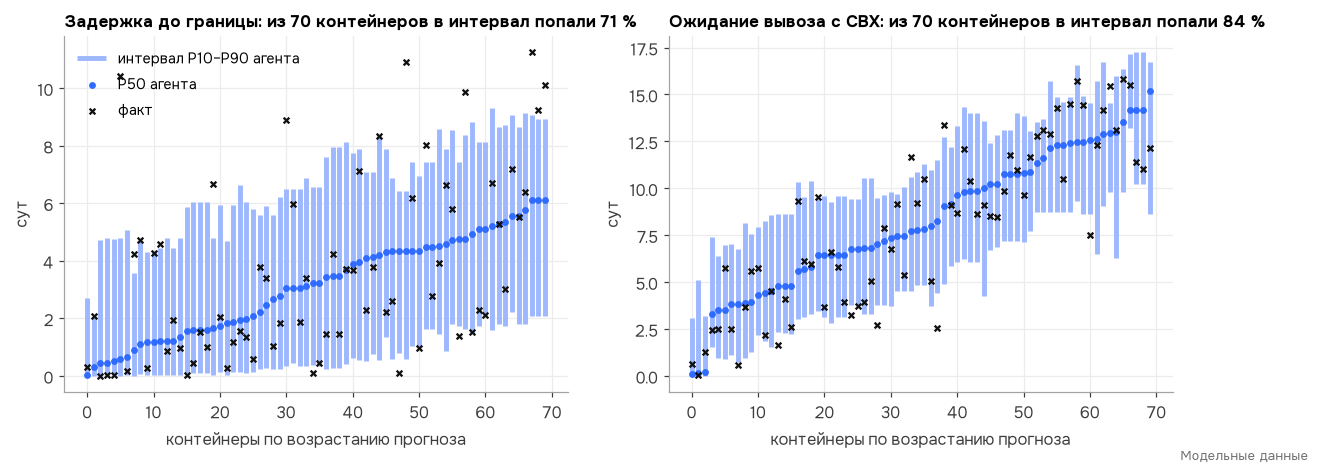

In [12]:
e = ev["general"].sample(70, random_state=3).reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (y, lo, mid, hi, title) in zip(axes, [("ext", "e10", "e50", "e90", "Задержка до границы"), ("svh", "w10", "w50", "w90", "Ожидание вывоза с СВХ")]):
    d = e.sort_values(mid).reset_index(drop=True)
    inside = (d[y] >= d[lo]) & (d[y] <= d[hi])
    ax.vlines(d.index, d[lo], d[hi], color=ACCENT_L, lw=3.2, label="интервал P10–P90 агента")
    ax.scatter(d.index, d[mid], color=ACCENT, s=12, zorder=3, label="P50 агента")
    ax.scatter(d.index, d[y], color=INK, s=14, marker="x", zorder=4, label="факт")
    ax.set_title(f"{title}: из 70 контейнеров в интервал попали {pct(inside.mean())}", fontsize=11)
    ax.set_xlabel("контейнеры по возрастанию прогноза")
    ax.set_ylabel("сут")
axes[0].legend(loc="upper left")
S.show(fig)

In [13]:
c0, c6 = cal["Обычный режим"], cal["Загрузка 2026 года"]
e0, e6 = err["Обычный режим"], err["Загрузка 2026 года"]
display(Markdown(
    f"**Вывод.** При обычной загрузке интервал честный: в P10–P90 попадают {pct(c0.iloc[0])} фактов до границы и "
    f"{pct(c0.iloc[2])} по СВХ. Вероятный срок ошибается на {pct(1 - e0.loc['ML-агент (P50)', 'до границы'])} меньше плана "
    f"экспедитора до границы и на {pct(1 - e0.loc['ML-агент (P50)', 'ожидание на СВХ'])} меньше по СВХ. "
    f"При загрузке 2026 года модель, обученная на обычной истории, недооценивает ожидание на СВХ: в интервал попадают только "
    f"{pct(c6.iloc[2])} фактов. Мы ее специально не переобучали, поэтому эффект агентов в этом режиме занижен. В реальной работе "
    f"модель нужно дообучать на свежих данных."))

**Вывод.** При обычной загрузке интервал честный: в P10–P90 попадают 78 % фактов до границы и 77 % по СВХ. Вероятный срок ошибается на 48 % меньше плана экспедитора до границы и на 41 % меньше по СВХ. При загрузке 2026 года модель, обученная на обычной истории, недооценивает ожидание на СВХ: в интервал попадают только 33 % фактов. Мы ее специально не переобучали, поэтому эффект агентов в этом режиме занижен. В реальной работе модель нужно дообучать на свежих данных.

<a id="6"></a>
## 6. Как это работает на одном варианте

Берем типичный вариант режима «загрузка 2026 года», в котором эффект агентов ближе всего к медиане по 500 вариантам,
и смотрим на него день за днем.

In [14]:
C26, L26, F26, DM26, COST26 = lib.rel_runs(RUNS, "general_2026", P, RES)
eff26 = (C26["P1"] - C26["P2"] - COST26) / (DM26 - C26["P1"])
seed6 = int((eff26 - eff26.median()).abs().idxmin())
tr = {r: lib.run_traced("general_2026", seed6, r) for r in RULES3}
print(f"Вариант {seed6}: с агентами прибыль выше на {pct(eff26[seed6], 1)} (медиана по вариантам — {pct(eff26.median(), 1)})")

Вариант 414: с агентами прибыль выше на 4,5 % (медиана по вариантам — 4,5 %)


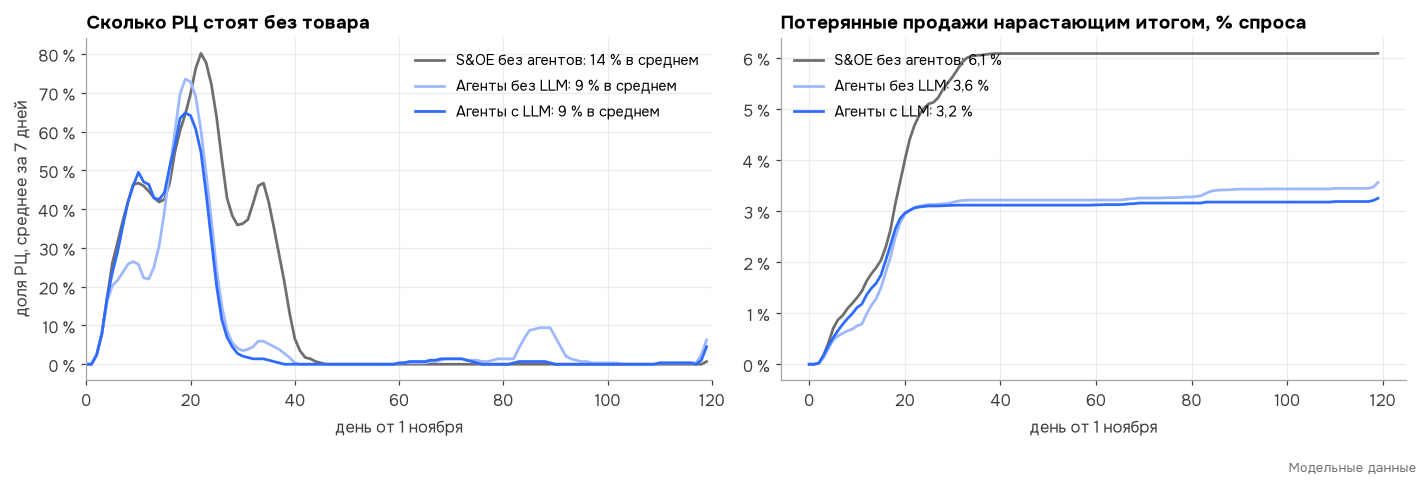

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
for r in RULES3:
    s, res = tr[r]
    out = (s.lost > 1e-6).mean(axis=0)
    ax1.plot(np.arange(s.T), pd.Series(out).rolling(7, min_periods=1).mean(), color=RULE_COLOR[r], lw=1.8,
             label=f"{RULE_NAME[r]}: {pct(out.mean())} в среднем")
    lost = np.cumsum(s.lost.sum(axis=0)) / s.demand.sum()
    ax2.plot(np.arange(s.T), lost, color=RULE_COLOR[r], lw=1.8, label=f"{RULE_NAME[r]}: {pct(lost[-1], 1)}")
ax1.set_xlim(0, tr["P1"][0].T)
ax1.yaxis.set_major_formatter(S.fmt_pct())
ax1.set_ylabel("доля РЦ, среднее за 7 дней")
ax1.set_title("Сколько РЦ стоят без товара")
ax1.set_xlabel("день от 1 ноября")
ax1.legend(loc="upper right")
ax2.yaxis.set_major_formatter(S.fmt_pct())
ax2.set_title("Потерянные продажи нарастающим итогом, % спроса")
ax2.set_xlabel("день от 1 ноября")
ax2.legend(loc="upper left")
fig.tight_layout()
S.show(fig)

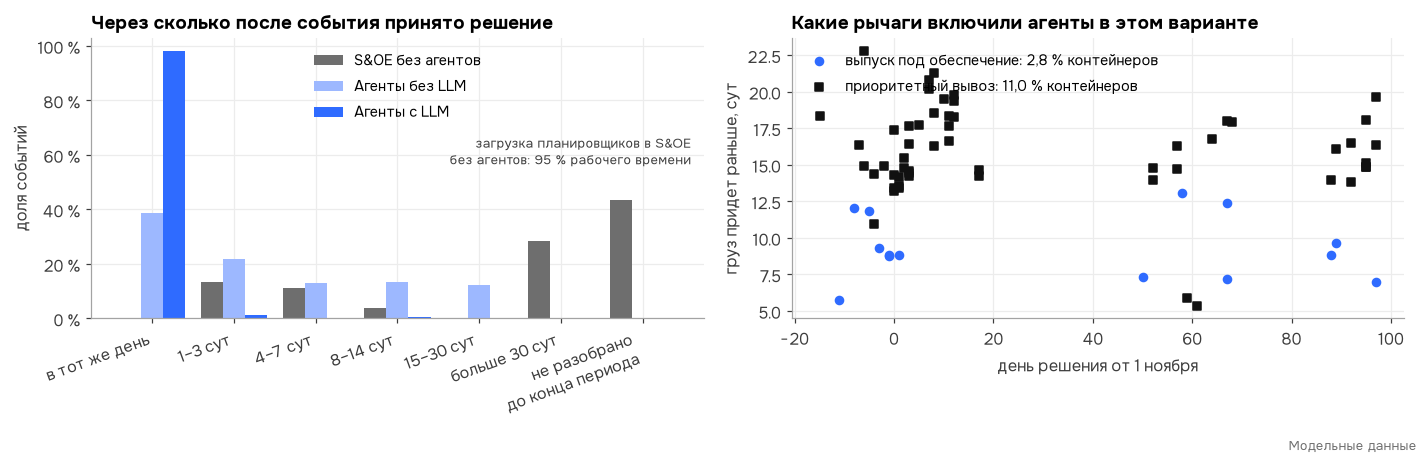

In [16]:
def lags(s):
    out = []
    for e in s.events:
        if e["t_dec"] is None:
            continue
        i = e["i"]
        true = {"eta": s.plan[i], "check": s.t_gw[i], "svh": s.t_rel[i]}[e["kind"]]
        out.append({"kind": e["kind"], "lag": e["t_dec"] - np.floor(true)})
    return pd.DataFrame(out)

L = {r: lags(tr[r][0]) for r in ("P1", "P2a", "P2")}
groups = [("в тот же день", 0, 0.5), ("1–3 сут", 0.5, 3.5), ("4–7 сут", 3.5, 7.5), ("8–14 сут", 7.5, 14.5), ("15–30 сут", 14.5, 30.5),
          ("больше 30 сут", 30.5, 1e9)]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.0))
xg = np.arange(len(groups) + 1)
for j, r in enumerate(("P1", "P2a", "P2")):
    lag = L[r].lag
    tot = len(tr[r][0].events)
    und = sum(e["t_dec"] is None for e in tr[r][0].events)
    share = [((lag >= lo) & (lag < hi)).sum() / tot for _, lo, hi in groups] + [und / tot]
    ax1.bar(xg + (j - 1) * 0.27, share, width=0.27, color=RULE_COLOR[r], label=RULE_NAME[r])
ax1.set_xticks(xg, [g[0] for g in groups] + ["не разобрано\nдо конца периода"], rotation=20, ha="right")
ax1.yaxis.set_major_formatter(S.fmt_pct())
ax1.set_ylabel("доля событий")
ax1.set_title("Через сколько после события принято решение")
ax1.text(0.98, 0.55, f"загрузка планировщиков в S&OE\nбез агентов: {pct(tr['P1'][1]['rho'])} рабочего времени", transform=ax1.transAxes,
         ha="right", fontsize=8.5, color=G1)
ax1.legend(loc="upper center")
log = pd.DataFrame(tr["P2"][0].lever_log)
for lv, c, mk, name in (("guarantee", ACCENT, "o", "выпуск под обеспечение"), ("priority", INK, "s", "приоритетный вывоз")):
    d = log[log.lever == lv]
    ax2.scatter(d.t, d.saved, color=c, marker=mk, s=28, label=f"{name}: {pct(len(d) / N0, 1)} контейнеров")
ax2.set_title("Какие рычаги включили агенты в этом варианте")
ax2.set_xlabel("день решения от 1 ноября")
ax2.set_ylabel("груз придет раньше, сут")
ax2.legend(loc="upper left")
fig.tight_layout()
S.show(fig)

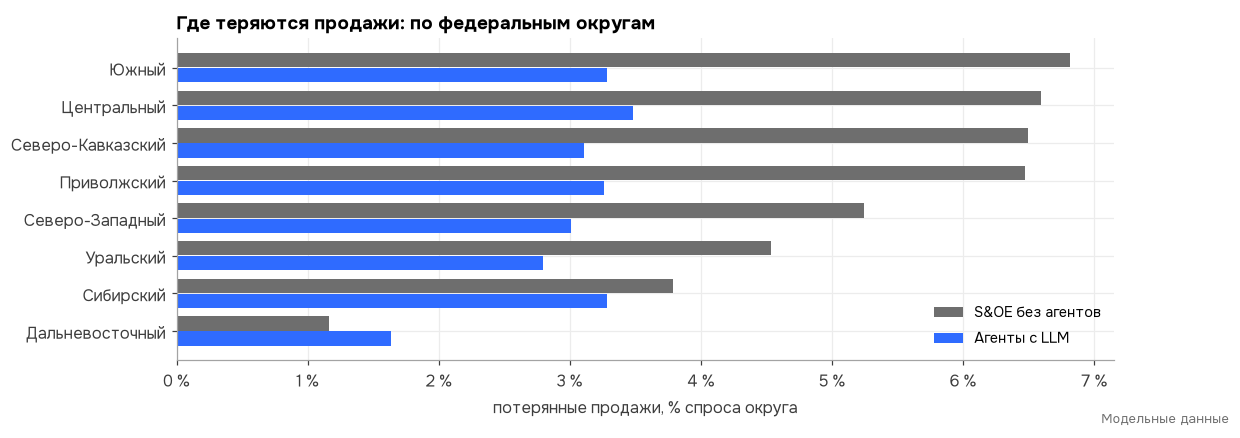

In [17]:
fdn = np.array(NET.fd)
rows = {}
for r in ("P1", "P2"):
    s = tr[r][0]
    rows[RULE_NAME[r]] = {f: s.lost[fdn == f].sum() / s.demand[fdn == f].sum() for f in sorted(set(fdn))}
fdl = pd.DataFrame(rows).sort_values(RULE_NAME["P1"])
fig, ax = plt.subplots(figsize=(11, 3.8))
y = np.arange(len(fdl))
ax.barh(y + 0.2, fdl[RULE_NAME["P1"]], height=0.38, color=RULE_COLOR["P1"], label=RULE_NAME["P1"])
ax.barh(y - 0.2, fdl[RULE_NAME["P2"]], height=0.38, color=RULE_COLOR["P2"], label=RULE_NAME["P2"])
ax.set_yticks(y, fdl.index)
ax.xaxis.set_major_formatter(S.fmt_pct())
ax.set_xlabel("потерянные продажи, % спроса округа")
ax.set_title("Где теряются продажи: по федеральным округам")
ax.legend(loc="lower right")
S.show(fig)

**Что видно.** В S&OE без агентов планировщики узнают о задержке из статусов, которые приходят раз в несколько дней и
иногда теряются, и разбирают ее в очереди вместе с обычной работой. Решение приходит через недели, когда рычаг уже не
успевает.

Агенты регионов составляют заявку по прогнозу спроса с учетом продаж, потерянных из-за пустых полок. Агенты без LLM
решают быстро только то, что пришло в структурированном виде, а новости из писем и PDF по-прежнему ждут планировщика.
С LLM агенты читают и их, поэтому почти все события разбираются в тот же день. Продаж теряется меньше во всех
округах.

<a id="7"></a>
## 7. Монте-Карло: результат и его надежность

Для каждого из 500 вариантов считаем, насколько изменилась прибыль при тех же спросе и задержках, но другом управлении.
95-процентный интервал для среднего получен бутстрепом. Стоимость работы агентов вычитается в каждом варианте.

In [18]:
def rel(sc, extra=None):
    C, L, F, DM, cost = lib.rel_runs(RUNS, sc, P, RES, extra)
    out = {"agents": (C["P1"] - C["P2"] - cost) / (DM - C["P1"]), "lost": (L["P1"] - L["P2"]) / L["P1"],
           "fill": F["P2"] - F["P1"], "gain": C["P1"] - C["P2"], "cost": cost,
           "llm": (C["P2a"] - C["P2"]) / (DM - C["P1"]), "risk": (C["P2 одна точка"] - C["P2"]) / (DM - C["P1"])}
    if "P1_full" in C:
        out["full"] = (C["P1_full"] - C["P2"] - cost) / (DM - C["P1_full"])
        out["speed"] = (C["P1"] - C["P1_full"]) / (DM - C["P1"])
    return pd.DataFrame(out)

R = {sc: rel(sc, STAFF_RUNS) for sc in MAIN}
rows = []
for sc, d in R.items():
    lo, hi = lib.boot_ci(d.agents)
    rows.append({"Режим": SCEN_NAME[sc],
                 "Прибыль с агентами выше, чем в S&OE без агентов": spct(d.agents.mean()),
                 "95 % интервал": f"{spct(lo)} … {spct(hi)}",
                 "Потерянные продажи с агентами": spct(-d.lost.mean(), 0),
                 "Доля продаж от спроса с агентами": pp(d.fill.mean()),
                 "Эффект больше стоимости работы агентов": S.times(d.gain.mean() / d.cost.mean()),
                 "Доля вариантов, где агенты в плюсе": pct((d.agents > 0).mean())})
S.table(pd.DataFrame(rows).set_index("Режим").T)

Режим,Обычный режим,Загрузка 2026 года,Сбой
"Прибыль с агентами выше, чем в S&OE без агентов","+2,8 %","+4,7 %","+2,9 %"
95 % интервал,"+2,7 % … +2,9 %","+4,5 % … +4,9 %","+2,8 % … +3,1 %"
Потерянные продажи с агентами,−35 %,−33 %,−24 %
Доля продаж от спроса с агентами,"+2,0 п. п.","+3,0 п. п.","+2,1 п. п."
Эффект больше стоимости работы агентов,в 27 раз,в 41 раз,в 28 раз
"Доля вариантов, где агенты в плюсе",98 %,100 %,100 %


<sub><i>Модельные данные.</i></sub>

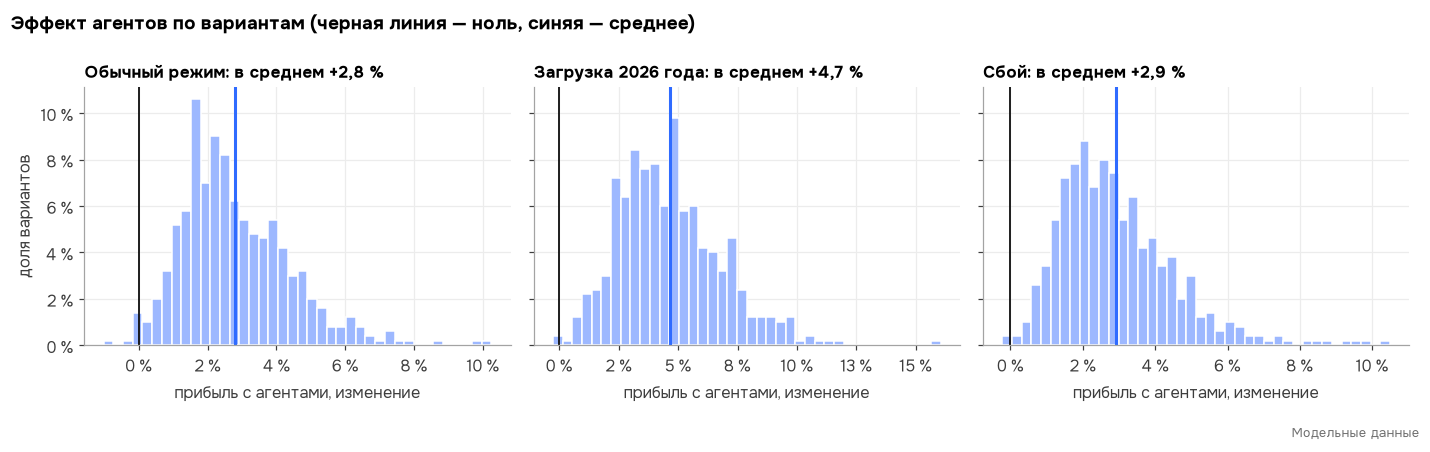

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, sc in zip(axes, MAIN):
    d = R[sc].agents
    ax.hist(d, bins=40, color=ACCENT_L, ec="white", weights=np.ones(len(d)) / len(d))
    ax.axvline(0, color=INK, lw=1.2)
    ax.axvline(d.mean(), color=ACCENT, lw=2)
    ax.xaxis.set_major_formatter(S.fmt_pct())
    ax.yaxis.set_major_formatter(S.fmt_pct())
    ax.set_title(f"{SCEN_NAME[sc]}: в среднем {spct(d.mean())}", fontsize=11)
    ax.set_xlabel("прибыль с агентами, изменение")
axes[0].set_ylabel("доля вариантов")
fig.suptitle("Эффект агентов по вариантам (черная линия — ноль, синяя — среднее)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
S.show(fig)

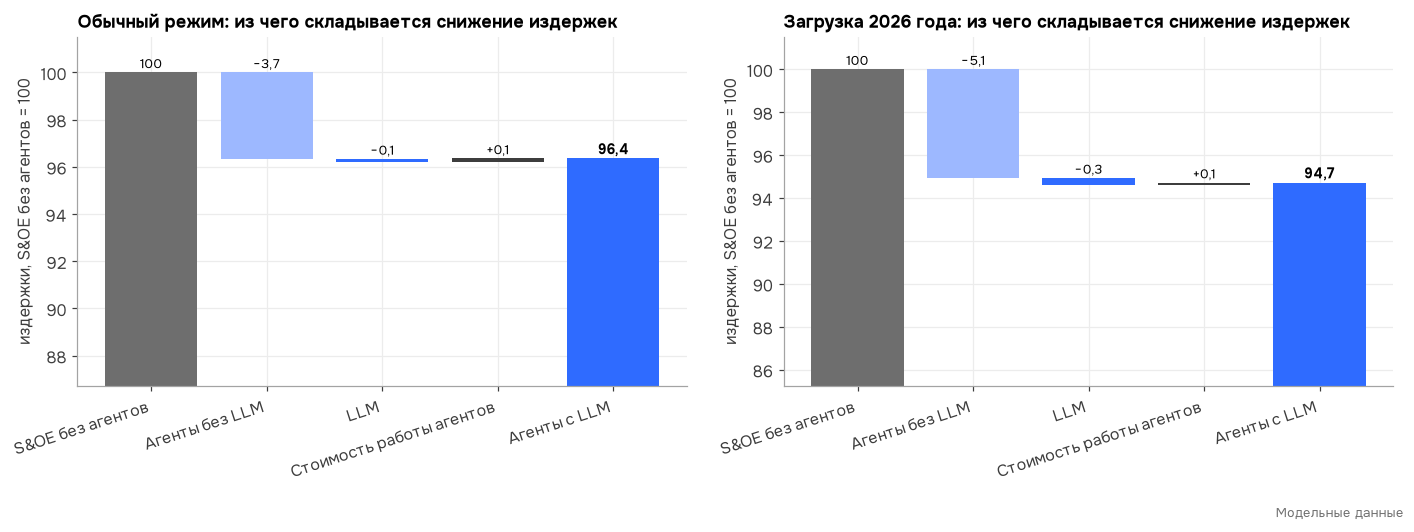

In [20]:
def waterfall(ax, sc):
    C, L, F, DM, cost = lib.rel_runs(RUNS, sc, P, RES)
    k = 100 / C["P1"].mean()
    steps = [("Агенты без LLM", -(C["P1"] - C["P2a"]).mean() * k), ("LLM", -(C["P2a"] - C["P2"]).mean() * k),
             ("Стоимость работы агентов", cost.mean() * k)]
    ax.bar(0, 100, color=RULE_COLOR["P1"])
    ax.text(0, 100, "100", ha="center", va="bottom", fontsize=9)
    level = 100.0
    for x, (name, v) in enumerate(steps, start=1):
        c = G1 if name.startswith("Стоимость") else (ACCENT_L if name.startswith("Агенты") else ACCENT)
        ax.bar(x, v, bottom=level, color=c)
        ax.text(x, max(level, level + v), f"{'+' if v > 0 else '−'}{num(abs(v), 1)}", ha="center", va="bottom", fontsize=9)
        level += v
    ax.bar(len(steps) + 1, level, color=RULE_COLOR["P2"])
    ax.text(len(steps) + 1, level, num(level, 1), ha="center", va="bottom", fontsize=9, weight="bold")
    ax.set_xticks(range(len(steps) + 2), ["S&OE без агентов"] + [s[0] for s in steps] + ["Агенты с LLM"], rotation=18, ha="right")
    ax.set_ylabel("издержки, S&OE без агентов = 100")
    ax.set_ylim(level * 0.9, 101.5)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, sc in zip(axes, ["general", "general_2026"]):
    waterfall(ax, sc)
    ax.set_title(f"{SCEN_NAME[sc]}: из чего складывается снижение издержек", fontsize=11.5)
fig.tight_layout()
S.show(fig)

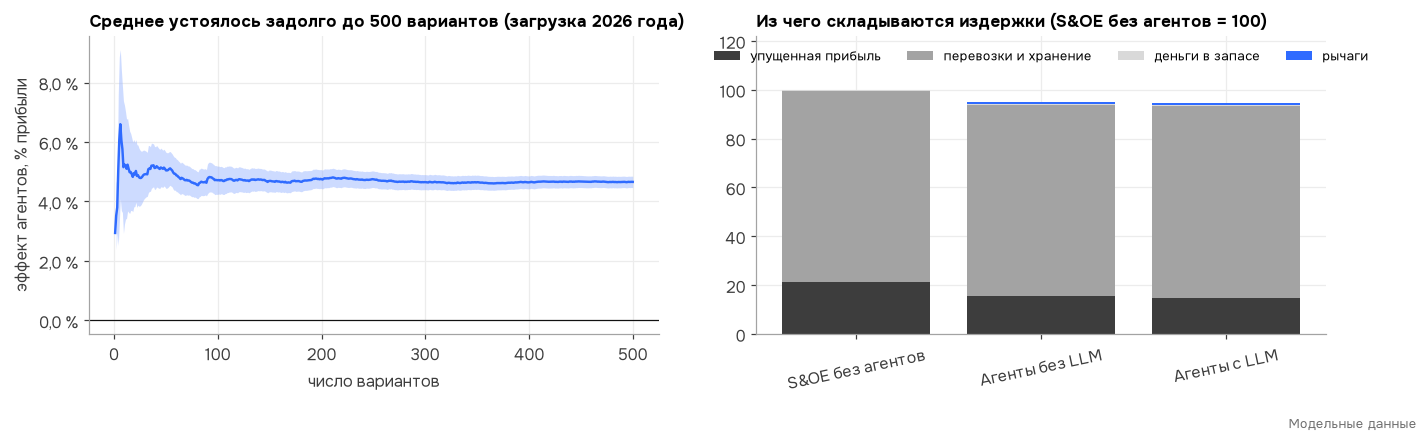

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
d = R["general_2026"].agents.values
n = np.arange(1, len(d) + 1)
m = np.cumsum(d) / n
se = np.array([d[:k].std(ddof=1) / np.sqrt(k) if k > 1 else np.nan for k in n])
axes[0].fill_between(n, m - 1.96 * se, m + 1.96 * se, color=ACCENT_L, alpha=0.5, lw=0)
axes[0].plot(n, m, color=ACCENT, lw=1.6)
axes[0].axhline(0, color=INK, lw=0.8)
axes[0].yaxis.set_major_formatter(S.fmt_pct(1))
axes[0].set_title("Среднее устоялось задолго до 500 вариантов (загрузка 2026 года)", fontsize=11)
axes[0].set_xlabel("число вариантов")
axes[0].set_ylabel("эффект агентов, % прибыли")
pol = RES["scenarios"]["general_2026"]["policies"]
base = pol["P1"]["total_cost"]["mean"]
parts = [("lost_profit", "упущенная прибыль", G1), ("logistics", "перевозки и хранение", G3), ("money", "деньги в запасе", G4), ("levers_cost", "рычаги", ACCENT)]
bottom = np.zeros(len(RULES3))
for k, name, c in parts:
    v = np.array([pol[r][k]["mean"] for r in RULES3]) / base * 100
    axes[1].bar([RULE_NAME[r] for r in RULES3], v, bottom=bottom, color=c, label=name)
    bottom += v
axes[1].set_ylim(0, bottom.max() * 1.22)
axes[1].set_title("Из чего складываются издержки (S&OE без агентов = 100)", fontsize=11)
axes[1].tick_params(axis="x", rotation=12)
axes[1].legend(ncol=4, fontsize=8.5, loc="upper center")
fig.tight_layout()
S.show(fig)

### Дело не только в нехватке людей

В S&OE без агентов планировщики загружены почти полностью, поэтому легко возразить: дайте им больше людей, и разница
исчезнет. Мы проверили это на тех же 500 вариантах: дали S&OE без агентов в 10 раз больше планировщиков, чтобы все
статусы и события разбирались в тот же день. Разница между S&OE без агентов при том же штате и
тем же S&OE без очереди — это эффект скорости. Разница между S&OE без очереди и вариантом «Агенты с LLM» — то, чего
людьми не добиться: прогноз сроков, оценка рычага по сценариям,
сверка документов до подачи, оценка потерянных продаж, ни один статус не теряется.

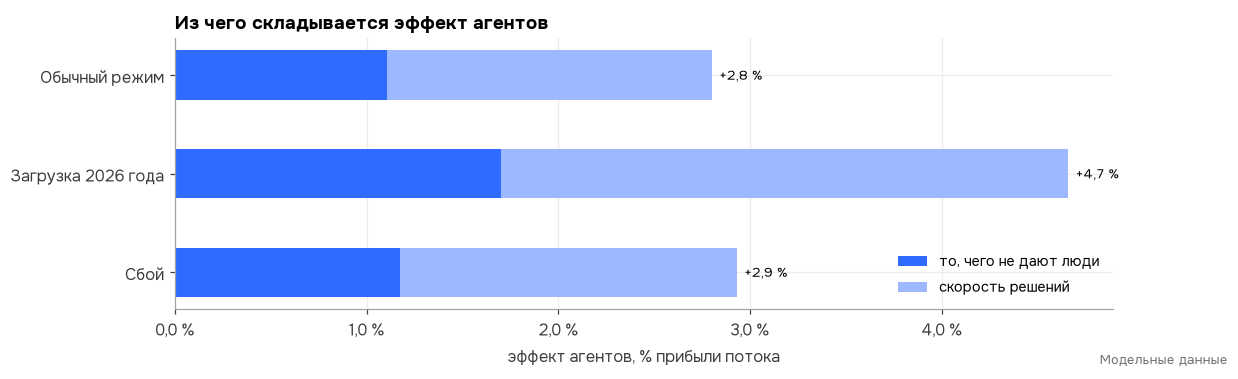

,Эффект агентов при том же штате,из него скорость решений,"Эффект агентов, если планировщиков сколько угодно",95 % интервал,"Доля вариантов, где агенты в плюсе"
Режим,,,,,
Обычный режим,"+2,8 %","+1,7 %","+1,1 %","+1,0 % … +1,2 %",90 %
Загрузка 2026 года,"+4,7 %","+3,0 %","+1,7 %","+1,5 % … +1,8 %",90 %
Сбой,"+2,9 %","+1,8 %","+1,2 %","+1,1 % … +1,2 %",91 %


<sub><i>Модельные данные.</i></sub>

In [22]:
rows, bars = [], []
for sc in MAIN:
    d = R[sc]
    lo, hi = lib.boot_ci(d.full)
    rows.append({"Режим": SCEN_NAME[sc], "Эффект агентов при том же штате": spct(d.agents.mean()),
                 "из него скорость решений": spct(d.speed.mean()), "Эффект агентов, если планировщиков сколько угодно": spct(d.full.mean()),
                 "95 % интервал": f"{spct(lo)} … {spct(hi)}", "Доля вариантов, где агенты в плюсе": pct((d.full > 0).mean())})
    bars.append((SCEN_NAME[sc], d.speed.mean(), d.agents.mean() - d.speed.mean()))
fig, ax = plt.subplots(figsize=(11, 3.2))
for j, (name, sp, ex) in enumerate(bars):
    ax.barh(j, ex, color=ACCENT, height=0.5, label="то, чего не дают люди" if j == 0 else None)
    ax.barh(j, sp, left=ex, color=ACCENT_L, height=0.5, label="скорость решений" if j == 0 else None)
    ax.text(ex + sp, j, f"  {spct(ex + sp)}", va="center", fontsize=9)
ax.set_yticks(range(len(bars)), [b[0] for b in bars])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(S.fmt_pct(1))
ax.set_xlabel("эффект агентов, % прибыли потока")
ax.set_title("Из чего складывается эффект агентов")
ax.legend(loc="lower right")
S.show(fig)
S.table(pd.DataFrame(rows).set_index("Режим"))

<a id="8"></a>
## 8. Как оркестратор решает, включать ли рычаг

У рычага есть цена, например надбавка за приоритетный вывоз, и выгода: товар придет раньше и продаж потеряется
меньше. Выгода зависит от того, когда придут остальные грузы. Если они успеют, ускорять этот контейнер незачем, а если
опоздают, без него регион останется пустым.

**Как было в первом расчете.** Оркестратор брал по каждому грузу один срок, вероятный по прогнозу ML-агентов, и
считал выгоду по нему. Получалось систематически мало: потеря продаж растет быстрее задержки. Если остальные грузы
опоздают, это стоит много, а если придут раньше, экономия маленькая. Средний срок этой асимметрии не видит, поэтому
оркестратор включал рычаги реже, чем нужно. Без ML-прогноза, по плану экспедитора, выходило даже лучше.

**Как стало.** Оркестратор разыгрывает 16 сценариев прихода всех грузов по прогнозу ML-агентов (их интервалам
P10–P90), считает выгоду рычага в каждом и берет среднюю. Рычаг включается, если средняя выгода больше цены.

In [23]:
rows = []
for sc in MAIN:
    pol = RES["scenarios"][sc]["policies"]
    d = R[sc]
    rows.append({"Режим": SCEN_NAME[sc],
                 "Прибыль выше, чем при оценке по одной точке": spct(d.risk.mean()),
                 "Доля вариантов, где новая оценка лучше": pct((d.risk > 0).mean()),
                 "Приоритетный вывоз: доля контейнеров, одна точка → сценарии":
                     f"{pct(pol['P2 одна точка']['levers']['priority'] / N0, 1)} → {pct(pol['P2']['levers']['priority'] / N0, 1)}",
                 "Выпуск под обеспечение: доля контейнеров, одна точка → сценарии":
                     f"{pct(pol['P2 одна точка']['levers']['guarantee'] / N0, 1)} → {pct(pol['P2']['levers']['guarantee'] / N0, 1)}",
                 "Вклад ML-прогноза сроков, % эффекта агентов": pct(RES["scenarios"][sc]["levers"]["eta_ml"]["rub"]["mean"] / d.gain.mean())})
S.table(pd.DataFrame(rows).set_index("Режим").T)

Режим,Обычный режим,Загрузка 2026 года,Сбой
"Прибыль выше, чем при оценке по одной точке","+0,6 %","+0,7 %","+0,6 %"
"Доля вариантов, где новая оценка лучше",91 %,91 %,93 %
"Приоритетный вывоз: доля контейнеров, одна точка → сценарии","2,6 % → 4,1 %","6,0 % → 8,0 %","2,8 % → 4,3 %"
"Выпуск под обеспечение: доля контейнеров, одна точка → сценарии","0,6 % → 1,4 %","1,1 % → 2,2 %","0,6 % → 1,4 %"
"Вклад ML-прогноза сроков, % эффекта агентов",4 %,4 %,3 %


<sub><i>Модельные данные.</i></sub>

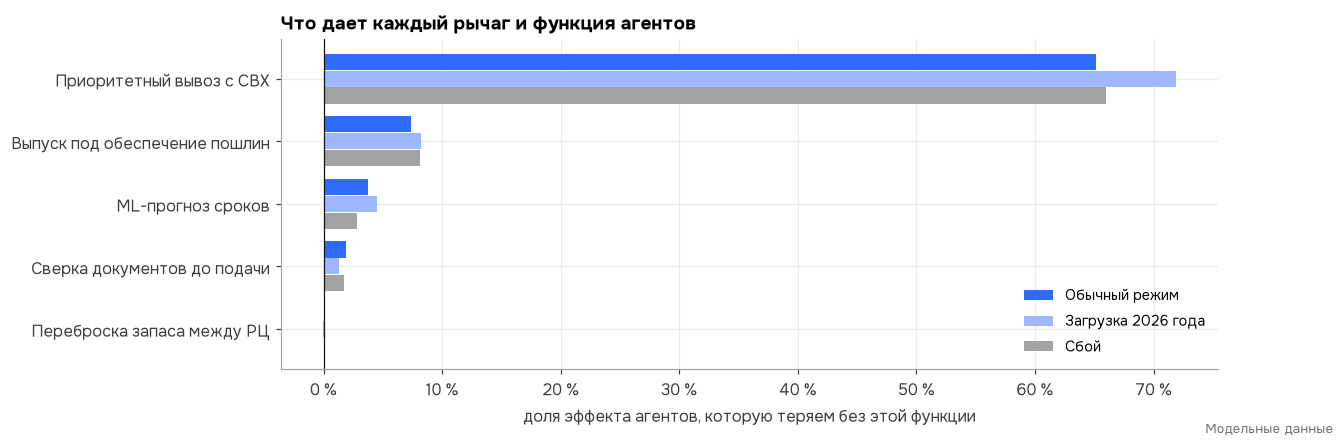

,Обычный режим,Загрузка 2026 года,Сбой
"Доля контейнеров, где агенты применили рычаг",,,
выпуск под обеспечение,"1,4 %","2,2 %","1,4 %"
приоритетный вывоз,"4,1 %","8,0 %","4,3 %"
переброска между РЦ,"0,0 %","0,0 %","0,0 %"
ошибка в документах найдена до подачи,"2,4 %","2,4 %","2,4 %"


<sub><i>Модельные данные.</i></sub>

In [24]:
gain = {sc: R[sc].gain.mean() for sc in MAIN}
biz = ["priority", "guarantee", "eta_ml", "doc_check", "transfer"]
LNAME = {"priority": "Приоритетный вывоз с СВХ", "guarantee": "Выпуск под обеспечение пошлин", "eta_ml": "ML-прогноз сроков",
         "doc_check": "Сверка документов до подачи", "transfer": "Переброска запаса между РЦ"}
lev = pd.DataFrame({SCEN_NAME[sc]: {LNAME[k]: RES["scenarios"][sc]["levers"][k]["rub"]["mean"] / gain[sc] for k in biz} for sc in MAIN})
lev = lev.loc[lev.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(11, 3.9))
y = np.arange(len(lev))
for j, (sc, c) in enumerate(zip(lev.columns, [ACCENT, ACCENT_L, G3])):
    ax.barh(y + (1 - j) * 0.27, lev[sc], height=0.26, color=c, label=sc)
ax.set_yticks(y, lev.index)
ax.axvline(0, color=INK, lw=0.8)
ax.xaxis.set_major_formatter(S.fmt_pct())
ax.set_xlabel("доля эффекта агентов, которую теряем без этой функции")
ax.set_title("Что дает каждый рычаг и функция агентов")
ax.legend(loc="lower right")
S.show(fig)
cnt = pd.DataFrame({SCEN_NAME[sc]: {k: v / N0 for k, v in RES["scenarios"][sc]["policies"]["P2"]["levers"].items()} for sc in MAIN}).rename(index={
    "guarantee": "выпуск под обеспечение", "priority": "приоритетный вывоз", "transfer": "переброска между РЦ",
    "doc_caught": "ошибка в документах найдена до подачи"})
S.table(cnt.map(lambda x: pct(x, 1)).rename_axis("Доля контейнеров, где агенты применили рычаг"))

In [25]:
lv = RES["scenarios"]["general"]["levers"]
g8 = gain["general"]
cnt8 = RES["scenarios"]["general"]["policies"]["P2"]["levers"]
fee = P["v5"]["svh"]["priority_fee_rub"]
display(Markdown(
    f"**Как читать.** Вклад показывает, какую долю эффекта агентов мы теряем, если убрать только эту функцию. Сумма вкладов не "
    f"равна 100 %, потому что функции дополняют друг друга. В обычном режиме больше всего дает приоритетный вывоз с СВХ: "
    f"{pct(lv['priority']['rub']['mean'] / g8)} эффекта. Агенты включают его у {pct(cnt8['priority'] / N0, 1)} контейнеров, "
    f"когда товар нужен срочно, а очередь на терминале длинная. Его цена ({pct(fee / CM, 1)} маржи контейнера) — наше "
    f"допущение, потому что в публичных тарифах такой услуги нет; это первое, что стоит проверить в пилоте. Выпуск под "
    f"обеспечение стоит {pct(guar / CM, 2)} маржи контейнера и снимает всю дополнительную проверку. Нужен он редко (у "
    f"{pct(cnt8['guarantee'] / N0, 1)} контейнеров), но каждый раз окупается многократно. ML-прогноз сроков теперь работает "
    f"в плюс ({pct(lv['eta_ml']['rub']['mean'] / g8)} эффекта): сценарии для оценки рычага строятся по его интервалам. "
    f"Переброска между РЦ почти не нужна, потому что общий запас в федеральном ТЦ делает ее лишней."))

**Как читать.** Вклад показывает, какую долю эффекта агентов мы теряем, если убрать только эту функцию. Сумма вкладов не равна 100 %, потому что функции дополняют друг друга. В обычном режиме больше всего дает приоритетный вывоз с СВХ: 65 % эффекта. Агенты включают его у 4,1 % контейнеров, когда товар нужен срочно, а очередь на терминале длинная. Его цена (4,0 % маржи контейнера) — наше допущение, потому что в публичных тарифах такой услуги нет; это первое, что стоит проверить в пилоте. Выпуск под обеспечение стоит 0,11 % маржи контейнера и снимает всю дополнительную проверку. Нужен он редко (у 1,4 % контейнеров), но каждый раз окупается многократно. ML-прогноз сроков теперь работает в плюс (4 % эффекта): сценарии для оценки рычага строятся по его интервалам. Переброска между РЦ почти не нужна, потому что общий запас в федеральном ТЦ делает ее лишней.

<a id="9"></a>
## 9. Где нужна LLM

LLM в схеме ничего не считает: все числа дают ML-агенты и расчеты оркестратора. Она нужна там, где
правила бессильны.

1. **Письма, PDF, сообщения и поток статусов.** Экспедиторы и брокеры сообщают о задержках письмами, сканами и в
   мессенджерах. Мы приняли, что в структурированном виде (трекинг, EDI, статусы терминалов и РЖД) приходит только
   40 % новостей. Без LLM остальные ждут планировщика, а сам поток статусов планировщики читают
   вручную и на разбор отклонений у них остается меньше времени.
2. **Документы любой формы.** Правила сверяют инвойс, упаковочный лист и декларацию только в стандартной форме, а это
   около 50 % комплектов. LLM читает и свободные формы поставщиков, и сканы, поэтому находит больше
   ошибок до подачи декларации.
3. **Объяснение и переписка.** LLM пишет человеку, почему предложен этот рычаг, и готовит письма брокеру и
   экспедитору. В деньгах мы это не считаем, но без этого решение агента трудно утвердить.

Ошибки LLM учтены: часть новостей она пропускает, и они идут к людям.

Функции дополняют друг друга, поэтому их вклады по отдельности в сумме меньше общего.

Режим,Обычный режим,Загрузка 2026 года,Сбой,"Сезонный, впритык"
"Доля эффекта агентов, которую дает LLM",3 %,6 %,4 %,38 %
"Издержки с LLM, изменение","−0,12 %","−0,36 %","−0,14 %","−4,38 %"
"Доля вариантов, где LLM дает плюс",59 %,65 %,62 %,99 %
в том числе письма и поток статусов,1 %,2 %,1 %,37 %
в том числе документы любой формы,1 %,1 %,1 %,1 %


<sub><i>Модельные данные.</i></sub>

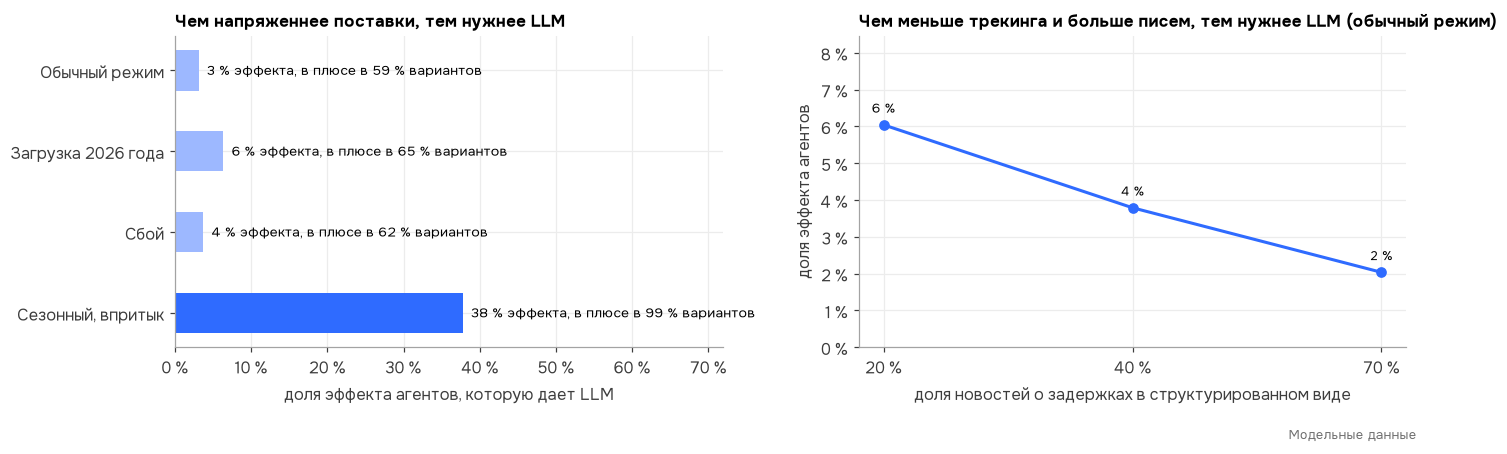

In [26]:
LLM_SC = ["general", "general_2026", "general_shock", "season_late"]
rows, parts = [], []
for sc in LLM_SC:
    C, L, F, DM, cost = lib.rel_runs(RUNS, sc, P, RES)
    lv = RES["scenarios"][sc]["levers"]
    g_sc = (C["P1"] - C["P2"]).mean()
    llm = C["P2a"] - C["P2"]
    rows.append({"Режим": SCEN_NAME[sc], "Доля эффекта агентов, которую дает LLM": pct(llm.mean() / g_sc),
                 "Издержки с LLM, изменение": spct(-(llm / C["P2a"]).mean(), 2),
                 "Доля вариантов, где LLM дает плюс": pct((llm > 0).mean()),
                 "в том числе письма и поток статусов": pct(lv["llm_news"]["rub"]["mean"] / g_sc),
                 "в том числе документы любой формы": pct(lv["llm_docs"]["rub"]["mean"] / g_sc)})
    parts.append((SCEN_NAME[sc], llm.mean() / g_sc, (llm > 0).mean()))
display(Markdown("Функции дополняют друг друга, поэтому их вклады по отдельности в сумме меньше общего."))
S.table(pd.DataFrame(rows).set_index("Режим").T)
ss = RES["sensitivity"]["structured_share"]
BP = (DM0 - C0["P1"]).mean()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.9))
y = np.arange(len(parts))
ax1.barh(y, [p[1] for p in parts], height=0.5, color=[ACCENT_L, ACCENT_L, ACCENT_L, ACCENT])
for j, (name, sh, win) in enumerate(parts):
    ax1.text(sh, j, f"  {pct(sh)} эффекта, в плюсе в {pct(win)} вариантов", va="center", fontsize=9)
ax1.set_yticks(y, [p[0] for p in parts])
ax1.invert_yaxis()
ax1.set_xlim(0, max(p[1] for p in parts) * 1.9)
ax1.xaxis.set_major_formatter(S.fmt_pct())
ax1.set_xlabel("доля эффекта агентов, которую дает LLM")
ax1.set_title("Чем напряженнее поставки, тем нужнее LLM", fontsize=11)
xs = [pct(r["value"]) for r in ss]
v = [r["llm"]["rub"]["mean"] / r["agents"]["rub"]["mean"] for r in ss]
ax2.plot(range(len(ss)), v, color=ACCENT, marker="o", lw=2)
for j, x in enumerate(v):
    ax2.annotate(pct(x), (j, x), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8.5)
ax2.set_xticks(range(len(ss)), xs)
ax2.set_ylim(0, max(v) * 1.4)
ax2.yaxis.set_major_formatter(S.fmt_pct())
ax2.set_xlabel("доля новостей о задержках в структурированном виде")
ax2.set_ylabel("доля эффекта агентов")
ax2.set_title("Чем меньше трекинга и больше писем, тем нужнее LLM (обычный режим)", fontsize=11)
fig.tight_layout()
S.show(fig)

**Вывод.** Главный денежный эффект дают расчеты агентов: прогноз сроков и выбор рычагов. LLM открывает им ту
часть информации, которая приходит не в таблицах, а в тексте, и снимает с планировщиков чтение потока писем. В спокойном
потоке это небольшая добавка, потому что планировщики успевают разобрать письма сами. Когда поставки впритык и каждый
день задержки стоит дорого, вклад LLM заметно растет. Чем меньше у компании трекинга и электронного обмена с
экспедиторами и брокерами, тем нужнее LLM. Еще одна функция в модели не учтена: LLM может готовить ответ на запрос
документов от таможни в тот же день. Это стоит проверить в пилоте.

<a id="10"></a>
## 10. Когда агенты нужнее всего

Обычный режим, 200 вариантов на каждую точку. Меняем одно допущение, остальные оставляем базовыми. Эффект
показан в процентах прибыли потока при базовых допущениях, значения допущений — относительно базы.

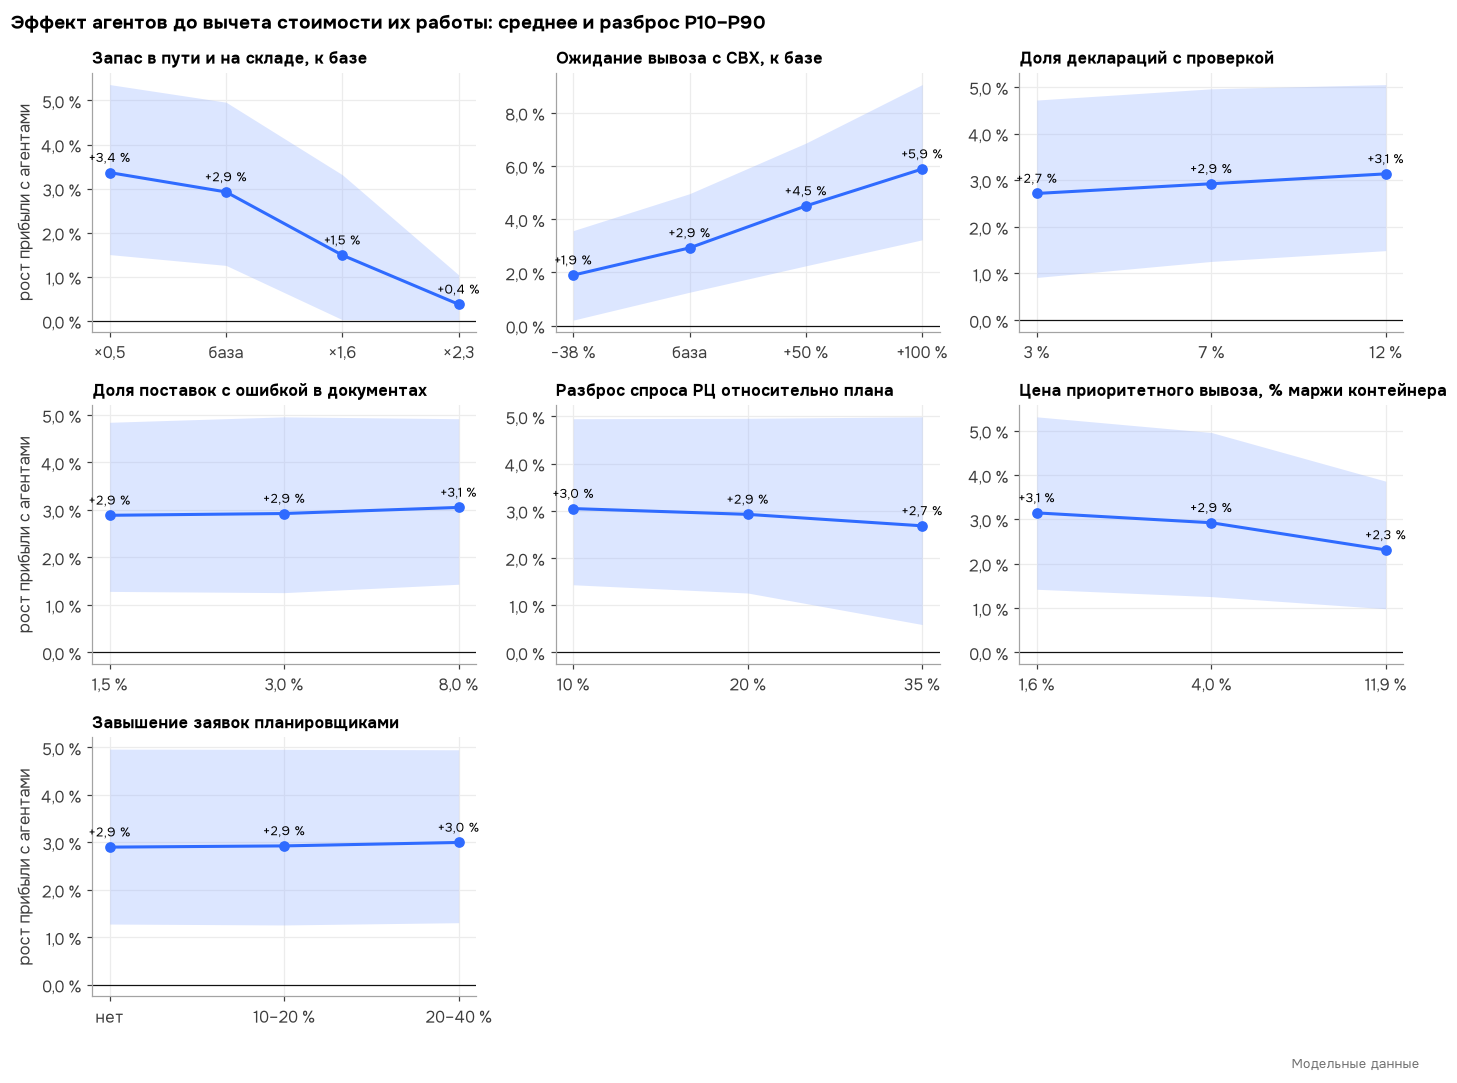

In [27]:
SENS = {"buffer_days": ("Запас в пути и на складе, к базе", lambda v: "база" if v[0] == -35 else f"×{num((10 + (-35 - v[0])) / 10, 1)}"),
        "svh_base_shift": ("Ожидание вывоза с СВХ, к базе", lambda v: "база" if v[0] == 8 else spct(v[0] / 8 - 1, 0)),
        "check_share": ("Доля деклараций с проверкой", lambda v: pct(v)),
        "doc_error_share": ("Доля поставок с ошибкой в документах", lambda v: pct(v, 1)),
        "level_sigma": ("Разброс спроса РЦ относительно плана", lambda v: pct(v)),
        "priority_fee": ("Цена приоритетного вывоза, % маржи контейнера", lambda v: pct(v / CM, 1)),
        "overorder": ("Завышение заявок планировщиками", lambda v: "нет" if v[1] == 0 else f"{num(100 * v[0])}–{num(100 * v[1])} %")}
sens = RES["sensitivity"]
fig, axes = plt.subplots(3, 3, figsize=(13, 9.6))
for ax in axes.flat[len(SENS):]:
    ax.axis("off")
for ax, (k, (title, f)) in zip(axes.flat, SENS.items()):
    rows = sens[k][::-1] if k == "buffer_days" else sens[k]
    xs = [f(r["value"]) for r in rows]
    ag = [r["agents"]["rub"]["mean"] / BP for r in rows]
    lo = [r["agents"]["rub"]["p10"] / BP for r in rows]
    hi = [r["agents"]["rub"]["p90"] / BP for r in rows]
    ax.fill_between(range(len(xs)), lo, hi, color=ACCENT_L, alpha=0.35, lw=0)
    ax.plot(range(len(xs)), ag, color=ACCENT, marker="o", lw=2)
    for j, v in enumerate(ag):
        ax.annotate(spct(v), (j, v), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8.5)
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_xticks(range(len(xs)), xs)
    ax.yaxis.set_major_formatter(S.fmt_pct(1))
    ax.set_title(title, fontsize=10.5)
for ax in axes[:, 0]:
    ax.set_ylabel("рост прибыли с агентами")
fig.suptitle("Эффект агентов до вычета стоимости их работы: среднее и разброс P10–P90", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
S.show(fig)

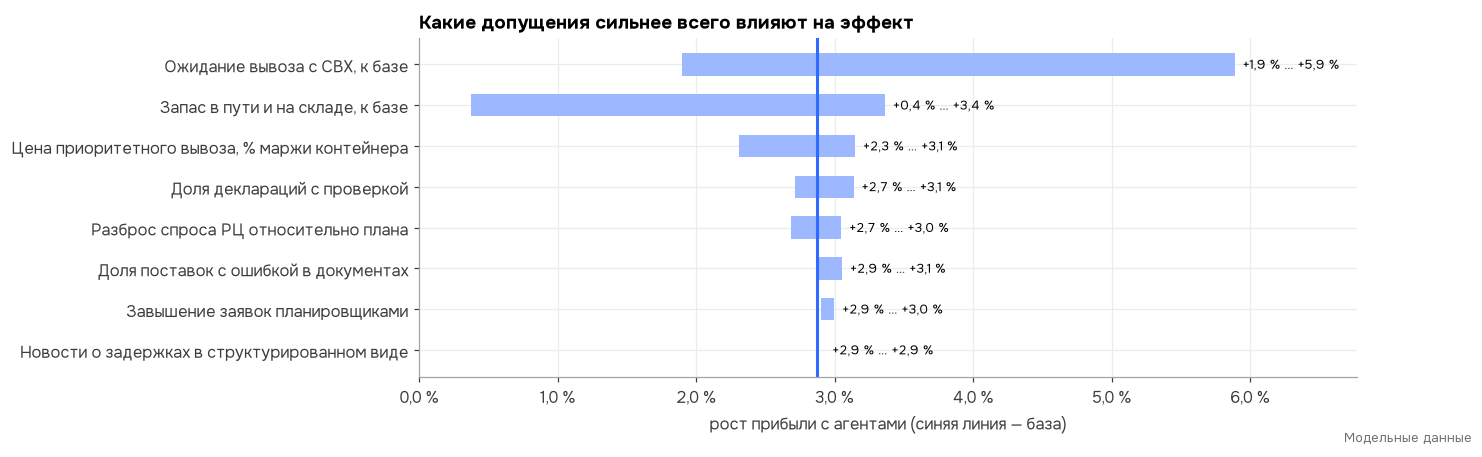

In [28]:
tor = []
for k, (title, f) in {**SENS, "structured_share": ("Новости о задержках в структурированном виде", None)}.items():
    v = [r["agents"]["rub"]["mean"] / BP for r in sens[k]]
    tor.append((title, min(v), max(v)))
tor.sort(key=lambda x: x[2] - x[1])
base = gain["general"] / BP
fig, ax = plt.subplots(figsize=(11, 4.0))
for j, (t, lo, hi) in enumerate(tor):
    ax.barh(j, hi - lo, left=lo, color=ACCENT_L, height=0.55)
    ax.text(hi, j, f"  {spct(lo)} … {spct(hi)}", va="center", fontsize=8.5)
ax.axvline(base, color=ACCENT, lw=2)
ax.set_xlim(0, max(t[2] for t in tor) * 1.15)
ax.set_yticks(range(len(tor)), [t for t, _, _ in tor])
ax.xaxis.set_major_formatter(S.fmt_pct(1))
ax.set_xlabel("рост прибыли с агентами (синяя линия — база)")
ax.set_title("Какие допущения сильнее всего влияют на эффект")
S.show(fig)

**Вывод.** Сильнее всего на эффект влияют загрузка терминалов и запас в пути. Завышение заявок планировщиками эффект
почти не меняет: выигрыш агентов дают скорость решений и рычаги, а не точность заявок. Чем дольше груз ждет вывоза, тем
ценнее ранний прогноз и приоритетный вывоз. Большой запас сам гасит задержки, и агенты почти ничего не меняют.
Бережливый поток без агентов теряет продажи на каждой задержке. Даже если приоритетный вывоз стоит втрое дороже
базового допущения, эффект сохраняется: агенты просто включают его реже.

<a id="11"></a>
## 11. Проверки модели

Автотесты лежат в `tests/test_v5.py`.

In [29]:
pol = {sc: RES["scenarios"][sc]["policies"] for sc in MAIN}
chk = [
    ("Баланс штук: пришло = продано + остаток + в пути, во всех вариантах", all(all(x["balance_ok"] for x in v.values()) for v in pol.values())),
    ("Одинаковый спрос у всех способов управления в одном варианте", True),
    ("ML-сроки: в интервал P10–P90 попадает 75–85 % прибытий (обычный режим)", 0.75 <= pol["general"]["P2"]["eta_cover"]["mean"] <= 0.85),
    ("Заявки завышают только планировщики; агенты регионов составляют заявку по прогнозу", True),
    ("Цена рычагов входит в издержки; с агентами издержки не выше", all(v["P2"]["total_cost"]["mean"] <= v["P1"]["total_cost"]["mean"] for v in pol.values())),
    ("Рычаг не знает будущего: о проверке таможни известно только после подачи декларации", True),
]
t = pd.DataFrame(chk, columns=["Проверка", "Выполнена"]).set_index("Проверка")
t["Выполнена"] = t["Выполнена"].map({True: "да", False: "нет"})
S.table(t)
milp = {SCEN_NAME[sc]: -RES["scenarios"][sc]["chain"]["milp_vs_rule"]["rub"]["mean"] / pol[sc]["P2"]["total_cost"]["mean"] for sc in MAIN}
display(Markdown("**Оптимизатор или простое правило.** Мы проверили, не лучше ли распределять запас федерального ТЦ линейной "
                 "задачей на 21 день вперед (HiGHS). Оказалось хуже простого правила «запас на срок доставки плюс страховой»: "
                 "издержки выше на " + "; ".join(f"{pct(v, 1)} ({k.lower()})" for k, v in milp.items()) +
                 ". При точности прогноза спроса, заложенной в модель, сложная оптимизация не окупается, поэтому запас распределяется "
                 "по правилу, а оркестратор решает, какие грузы ускорять."))

,Выполнена
Проверка,
"Баланс штук: пришло = продано + остаток + в пути, во всех вариантах",да
Одинаковый спрос у всех способов управления в одном варианте,да
ML-сроки: в интервал P10–P90 попадает 75–85 % прибытий (обычный режим),да
Заявки завышают только планировщики; агенты регионов составляют заявку по прогнозу,да
Цена рычагов входит в издержки; с агентами издержки не выше,да
Рычаг не знает будущего: о проверке таможни известно только после подачи декларации,да


<sub><i>Модельные данные.</i></sub>

**Оптимизатор или простое правило.** Мы проверили, не лучше ли распределять запас федерального ТЦ линейной задачей на 21 день вперед (HiGHS). Оказалось хуже простого правила «запас на срок доставки плюс страховой»: издержки выше на 4,4 % (обычный режим); 4,8 % (загрузка 2026 года); 3,8 % (сбой). При точности прогноза спроса, заложенной в модель, сложная оптимизация не окупается, поэтому запас распределяется по правилу, а оркестратор решает, какие грузы ускорять.

<a id="12"></a>
## 12. Пример: разбор одного контейнера агентами

Запись разбора с LLM на модельных данных (`agents/recordings/K-382.json`): запросы к LLM настоящие, а контейнер K-382 и
его данные взяты из модели. В модели K-382 стоит на дополнительной проверке в Забайкальске, а в нескольких РЦ товар
кончается на этой неделе. Каждый агент вызывает расчеты модели и
пишет вывод. Числа в тексте сверяются с результатами расчетов: если LLM написала число, которого нет в
расчете, вместо ее текста показывается текст правила.

In [30]:
rec = json.loads((ROOT / "agents/recordings/K-382.json").read_text(encoding="utf-8"))
TITLE = {"ext": "Агент внешней доставки", "customs": "Агент таможни", "internal": "Агент внутренней доставки",
         "regions": "Агенты регионов", "orchestrator": "Оркестратор S&OE-цикла"}
DO = {"ext": "срок прихода на границу и опоздание к плану", "customs": "сверка документов, статус проверки, выпуск под обеспечение",
      "internal": "ожидание вывоза с СВХ, срок до федерального ТЦ, приоритетный вывоз",
      "regions": "в каких РЦ товар кончится раньше всего и во что обходится задержка", "orchestrator": "выбор рычага, порядок регионов, карточка решения"}
rows = []
for a in TITLE:
    calls = [e["data"]["tool"] for e in rec if e["type"] == "tool_call" and e["agent"] == a]
    fin = next(e["data"] for e in rec if e["type"] == "agent_finished" and e["agent"] == a)
    rows.append({"Агент": TITLE[a], "Что выяснил": DO[a], "Расчеты": ", ".join(dict.fromkeys(calls)),
                 "Кто написал вывод": "LLM" if fin["mode"] == "llm" else "правило (LLM написала число не из расчета)",
                 "Числа сверены": "все" if fin["numbers_check"]["ok"] else "нет"})
S.table(pd.DataFrame(rows).set_index("Агент"))

,Что выяснил,Расчеты,Кто написал вывод,Числа сверены
Агент,,,,
Агент внешней доставки,срок прихода на границу и опоздание к плану,get_tracking,LLM,все
Агент таможни,"сверка документов, статус проверки, выпуск под...","check_documents, customs_status",правило (LLM написала число не из расчета),все
Агент внутренней доставки,"ожидание вывоза с СВХ, срок до федерального ТЦ...","svh_status, rail_eta",правило (LLM написала число не из расчета),все
Агенты регионов,в каких РЦ товар кончится раньше всего и во чт...,top_regions,LLM,все
Оркестратор S&OE-цикла,"выбор рычага, порядок регионов, карточка решения","evaluate_levers, allocation_plan, create_decision",LLM,все


<sub><i>Модельные данные.</i></sub>

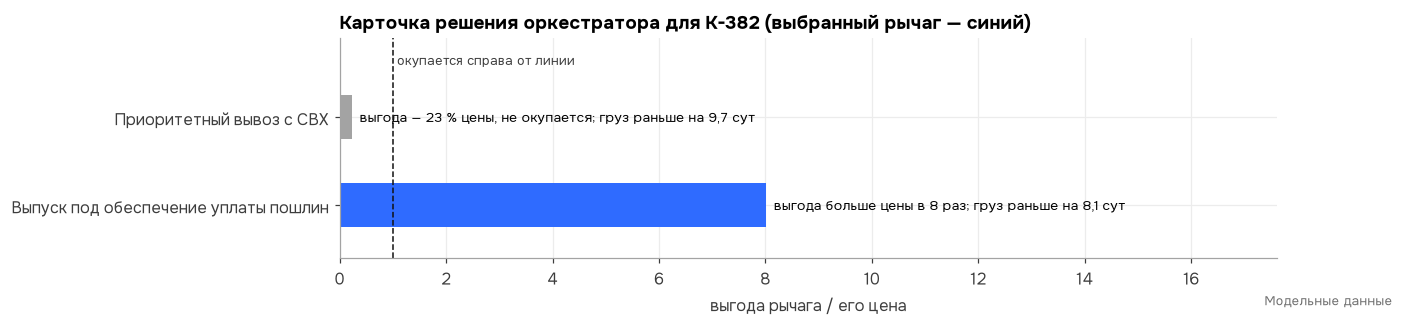

**Решение:** «Выпуск под обеспечение уплаты пошлин». Выгода больше цены в 8 раз, груз придет на 8,1 сут раньше. Товар сначала уходит в РЦ: Краснодар, Тюмень, Москва Восток, Ярославль. Решение утверждает человек: в пределах лимита сразу, дороже лимита — на S&OE-встрече.

In [31]:
card = next(e["data"] for e in rec if e["type"] == "decision_card")
opt = pd.DataFrame(card["options"])
opt["ratio"] = opt.benefit_rub / opt.cost_rub
fig, ax = plt.subplots(figsize=(11, 2.6))
y = np.arange(len(opt))
ax.barh(y, opt.ratio, color=[ACCENT if l == card["lever"] else G3 for l in opt.id], height=0.5)
ax.axvline(1, color=INK, lw=1, ls="--")
ax.text(1, len(opt) - 0.45, " окупается справа от линии", fontsize=8.5, color=G1, va="bottom")
for j, r in opt.iterrows():
    txt = f"выгода больше цены {S.times(r.ratio)}" if r.ratio >= 1 else f"выгода — {pct(r.ratio)} цены, не окупается"
    ax.text(r.ratio, j, f"  {txt}; груз раньше на {num(r.saved_days, 1)} сут", va="center", fontsize=9)
ax.set_yticks(y, opt.title)
ax.set_ylim(-0.6, len(opt) - 0.1)
ax.set_xlim(0, max(opt.ratio.max(), 1) * 2.2)
ax.set_xlabel("выгода рычага / его цена")
ax.set_title("Карточка решения оркестратора для K-382 (выбранный рычаг — синий)")
S.show(fig)
regs = [S.anon(r) for r in card["regions"]]
chosen = opt[opt.id == card["lever"]].iloc[0]
display(Markdown(f"**Решение:** «{chosen.title}». Выгода больше цены {S.times(chosen.ratio)}, груз придет на "
                 f"{num(chosen.saved_days, 1)} сут раньше. Товар сначала уходит в РЦ: {', '.join(regs)}. Решение утверждает "
                 f"человек: в пределах лимита сразу, дороже лимита — на S&OE-встрече."))

<a id="13"></a>
## 13. Приложение: сезонный товар

Для сравнения — сезонный товар с пиком продаж в декабре. Его закупают с запасом на весь сезон, а остаток после сезона
уценивают. Большой запас сам гасит задержки, поэтому агенты почти не нужны, пока товар не начинает приходить впритык
к продажам.

In [32]:
rows = []
for sc in ("season", "season_late"):
    C, L, F, DM, cost = lib.rel_runs(RUNS, sc, P, RES)
    p1 = C["P1"].mean()
    rows.append({"Режим": SCEN_NAME[sc], **{f"Издержки: {RULE_NAME[r]}": num(C[r].mean() / p1 * 100, 1) for r in RULES3},
                 "Издержки: Агенты с LLM, изменение после стоимости работы агентов": spct(-((C["P1"] - C["P2"]).mean() - cost.mean()) / C["P1"].mean()),
                 "Потерянные продажи: Агенты с LLM, изменение": spct(-(L["P1"] - L["P2"]).mean() / max(L["P1"].mean(), 1e-9), 0)})
display(Markdown("Издержки показаны индексом: S&OE без агентов = 100."))
S.table(pd.DataFrame(rows).set_index("Режим").T)

Издержки показаны индексом: S&OE без агентов = 100.

Режим,Сезонный товар,"Сезонный, впритык"
Издержки: S&OE без агентов,"100,0","100,0"
Издержки: Агенты без LLM,"100,0","93,2"
Издержки: Агенты с LLM,"100,0","89,0"
"Издержки: Агенты с LLM, изменение после стоимости работы агентов","+0,0 %","−10,9 %"
"Потерянные продажи: Агенты с LLM, изменение",−37 %,−30 %


<sub><i>Модельные данные.</i></sub>

<a id="14"></a>
## 14. Ограничения и что нужно для пилота

**Ограничения**

- Все данные модельные. Спрос, сроки, ошибки в документах, проверки и экономика синтетические, параметры взяты из
  открытых источников или заданы допущениями с диапазоном. Результат показывает механизм и порядок эффекта, но не
  прогнозирует его для реальной компании.
- Контейнер однородный: одна условная товарная категория, без смешанных контейнеров и приоритета артикулов.
- ML-агенты обучены на истории обычной загрузки и не переобучались под режим 2026 года.
- Цена приоритетного вывоза с СВХ и доля информации в структурированном виде — допущения. Оба проверены на
  чувствительность, но в пилоте их нужно измерить.
- Оценку рычага по сценариям мы добавили после первого расчета, когда увидели, что оценка по одной точке занижает
  выгоду. Оба варианта есть в результатах (раздел 8).
- Схема «весь импорт через федеральный ТЦ» — допущение модели. Где ставить хабы, решается в S&OP, здесь это не считается.

**Что нужно для пилота (8–10 недель, одна точка входа)**

1. Выгрузки за год: статусы контейнеров от экспедитора, даты выпуска деклараций и запросов документов, продажи и
   остатки РЦ по дням. На них обучаются агенты сроков.
2. Сколько статусов приходит в структурированном виде, а сколько письмами. От этого зависит вклад LLM.
3. Договоренность с терминалами о приоритетном вывозе и его цене: это главный по эффекту рычаг.
4. Договор с банком о гарантиях в пользу таможни и порядок их выдачи по запросу: это самый дешевый рычаг.
5. Сравнение до и после на одной точке входа: опоздание к плану, доля дней без товара в РЦ, потерянные продажи. Это
   те же показатели, что в модели.

**Как воспроизвести**

```bash
python3 -m venv .venv && .venv/bin/pip install -r requirements.txt nbformat nbconvert ipykernel
.venv/bin/python -m src.v5.experiments                 # results.json и runs.csv
.venv/bin/python -m src.v5.experiments --staff-check   # runs_staff.csv
.venv/bin/python -m analysis.build                     # этот отчет: report.ipynb и REPORT.md
```

*Все данные в отчете модельные.*